# Cloud & IT Support Copilot

**Course:** AIMLZG 549 – API-driven Cloud Native Solutions  
**Assignment:** Assignment II  
**Domain:** IT Service Management / Technical Support

## Project objective

Develop an interactive AI-assisted support application that helps IT support teams process incoming support tickets through three connected Natural Language Processing tasks:

1. **Ticket classification:** Predict the appropriate support category using a fine-tuned DistilBERT model.
2. **Ticket summarisation:** Generate concise, factual ticket summaries using Qwen2.5-3B-Instruct.
3. **Documentation-grounded troubleshooting:** Retrieve relevant support documentation using embeddings and FAISS, then generate a response using Qwen2.5-3B-Instruct.

The application combines these tasks in a single Gradio interface.

## Technology stack

| Component | Technology |
|---|---|
| Classification | Fine-tuned DistilBERT |
| Summarisation | Qwen2.5-3B-Instruct (4-bit quantisation) |
| Text embeddings | all-MiniLM-L6-v2 |
| Vector search | FAISS |
| Application interface | Gradio |
| Development environment | Google Colab with GPU |

## Project structure

The notebook is organised into four assignment components:

- **Section I:** AI application and three NLP subtasks
- **Section II:** Dataset selection and model fine-tuning
- **Section III:** Retrieval-Augmented Generation (RAG)
- **Section IV:** Situated Learning – Workplace Application

In [1]:

# ============================================================
# STAGE 2: ENVIRONMENT AND PROJECT SETUP
# ============================================================

# 1. Install required libraries
%pip install -q \
    transformers \
    accelerate \
    bitsandbytes \
    datasets \
    evaluate \
    scikit-learn \
    sentence-transformers \
    faiss-cpu \
    gradio \
    pypdf \
    beautifulsoup4 \
    lxml \
    huggingface_hub \
    requests

# 2. Import libraries
import os
import gc
import json
import random
import re
import time
import numpy as np
import pandas as pd
from pathlib import Path

import torch

# 3. Set random seeds for reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# 4. Mount Google Drive
from google.colab import drive
drive.mount("/content/drive")

# 5. Define the project root directory
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Cloud_IT_Support_Copilot"
)

# 6. Create all required project directories
DIRECTORIES = [
    "datasets/raw",
    "datasets/processed",
    "datasets/situated_learning",
    "corpus/raw",
    "corpus/processed",
    "models/classifier",
    "models/generator",
    "rag/chunks",
    "rag/embeddings",
    "rag/index",
    "metadata",
    "reports",
    "outputs/classification",
    "outputs/summarisation",
    "outputs/rag",
    "outputs/evaluation",
    "outputs/situated_learning"
]

for directory in DIRECTORIES:
    (PROJECT_ROOT / directory).mkdir(
        parents=True,
        exist_ok=True
    )

# 7. Display environment information
print("=" * 55)
print("CLOUD & IT SUPPORT COPILOT")
print("Environment initialised successfully")
print("=" * 55)

print("\nProject directory:")
print(PROJECT_ROOT)

print("\nHardware information:")
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    gpu_memory = (
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3)
    )

    print("GPU memory:", round(gpu_memory, 2), "GB")
else:
    print("WARNING: No GPU detected. Change the Colab runtime to T4 GPU.")

print("\nProject directories created:")
for directory in DIRECTORIES:
    print("-", directory)


Mounted at /content/drive
CLOUD & IT SUPPORT COPILOT
Environment initialised successfully

Project directory:
/content/drive/MyDrive/Cloud_IT_Support_Copilot

Hardware information:
PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB

Project directories created:
- datasets/raw
- datasets/processed
- datasets/situated_learning
- corpus/raw
- corpus/processed
- models/classifier
- models/generator
- rag/chunks
- rag/embeddings
- rag/index
- metadata
- reports
- outputs/classification
- outputs/summarisation
- outputs/rag
- outputs/evaluation
- outputs/situated_learning


## Dataset Selection and Preparation

The project uses the Kaggle **IT Service Ticket Classification Dataset**, containing labelled IT support ticket descriptions.

The dataset is used to train and evaluate the ticket classification model. It contains eight support categories:

- Access
- Administrative rights
- HR Support
- Hardware
- Internal Project
- Miscellaneous
- Purchase
- Storage

The dataset is divided into training, validation and test subsets using stratified sampling. This preserves the approximate category distribution across the three subsets.

Ticket descriptions are tokenised using the pretrained DistilBERT tokenizer, preparing the data for baseline evaluation and fine-tuning.

In [3]:

# ============================================================
# STAGE 3: DATASET LOADING, PREPARATION AND TOKENISATION
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from datasets import Dataset, DatasetDict
from transformers import AutoTokenizer

# 1. Load the Kaggle dataset
DATA_PATH = PROJECT_ROOT / "datasets/raw/all_tickets_processed_improved_v3.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Please place all_tickets_processed_improved_v3.csv "
        "inside the datasets/raw folder in Google Drive."
    )

tickets_df = pd.read_csv(DATA_PATH)

# 2. Validate and clean required fields
required_columns = ["Document", "Topic_group"]

if not all(column in tickets_df.columns for column in required_columns):
    raise ValueError(
        f"Expected columns {required_columns}; "
        f"found {tickets_df.columns.tolist()}"
    )

tickets_df = tickets_df[required_columns].copy()

tickets_df["Document"] = (
    tickets_df["Document"]
    .fillna("")
    .astype(str)
    .str.strip()
)

tickets_df["Topic_group"] = (
    tickets_df["Topic_group"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# Remove records with empty descriptions or labels
tickets_df = tickets_df[
    (tickets_df["Document"] != "") &
    (tickets_df["Topic_group"] != "")
].copy()

# 3. Dataset quality assessment
tickets_df["word_count"] = (
    tickets_df["Document"].str.split().str.len()
)

print("DATASET OVERVIEW")
print("=" * 55)
print("Number of records:", f"{len(tickets_df):,}")
print("Number of categories:", tickets_df["Topic_group"].nunique())
print("Duplicate descriptions:", tickets_df["Document"].duplicated().sum())
print("Average ticket length:", round(tickets_df["word_count"].mean(), 2), "words")
print("Median ticket length:", int(tickets_df["word_count"].median()), "words")
print("Maximum ticket length:", int(tickets_df["word_count"].max()), "words")

print("\nCATEGORY DISTRIBUTION")
display(tickets_df["Topic_group"].value_counts().rename("Ticket Count").to_frame())

# 4. Encode the eight support categories
label_encoder = LabelEncoder()

tickets_df["label"] = label_encoder.fit_transform(
    tickets_df["Topic_group"]
)

label_names = list(label_encoder.classes_)
num_labels = len(label_names)

id2label = {i: label for i, label in enumerate(label_names)}
label2id = {label: i for i, label in enumerate(label_names)}

print("\nLABEL MAPPING")
for index, category in id2label.items():
    print(f"{index}: {category}")

# 5. Create stratified 80/10/10 train, validation and test splits
train_df, temp_df = train_test_split(
    tickets_df,
    test_size=0.20,
    random_state=SEED,
    stratify=tickets_df["label"]
)

validation_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)

print("\nDATASET SPLIT")
print("Training:", f"{len(train_df):,}")
print("Validation:", f"{len(validation_df):,}")
print("Test:", f"{len(test_df):,}")

# 6. Load the DistilBERT tokenizer
MODEL_NAME = "distilbert-base-uncased"
MAX_LENGTH = 256

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# 7. Convert the splits into Hugging Face datasets
def create_hf_dataset(dataframe):
    dataset = Dataset.from_pandas(
        dataframe[["Document", "label"]].reset_index(drop=True)
    )
    return dataset.rename_column("Document", "text")

raw_datasets = DatasetDict({
    "train": create_hf_dataset(train_df),
    "validation": create_hf_dataset(validation_df),
    "test": create_hf_dataset(test_df)
})

# 8. Tokenise ticket descriptions
def tokenize_tickets(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

tokenized_datasets = raw_datasets.map(
    tokenize_tickets,
    batched=True
)

# 9. Prepare label arrays for model evaluation
y_train = train_df["label"].to_numpy()
y_validation = validation_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

# 10. Save dataset metadata
dataset_metadata = {
    "dataset": "IT Service Ticket Classification Dataset",
    "source": "Kaggle",
    "records": len(tickets_df),
    "categories": label_names,
    "label_mapping": {str(k): v for k, v in id2label.items()},
    "train_records": len(train_df),
    "validation_records": len(validation_df),
    "test_records": len(test_df),
    "model": MODEL_NAME,
    "max_length": MAX_LENGTH,
    "random_seed": SEED
}

metadata_path = PROJECT_ROOT / "metadata/dataset_metadata.json"

with open(metadata_path, "w") as file:
    json.dump(dataset_metadata, file, indent=4)

print("\nTOKENISATION")
for split_name, dataset in tokenized_datasets.items():
    print(f"{split_name}: {len(dataset):,} records")

print("\nDataset preparation completed successfully.")
print("Metadata saved to:", metadata_path)


DATASET OVERVIEW
Number of records: 47,837
Number of categories: 8
Duplicate descriptions: 0
Average ticket length: 43.6 words
Median ticket length: 26 words
Maximum ticket length: 981 words

CATEGORY DISTRIBUTION


,Ticket Count
Topic_group,
Hardware,13617
HR Support,10915
Access,7125
Miscellaneous,7060
Storage,2777
Purchase,2464
Internal Project,2119
Administrative rights,1760



LABEL MAPPING
0: Access
1: Administrative rights
2: HR Support
3: Hardware
4: Internal Project
5: Miscellaneous
6: Purchase
7: Storage

DATASET SPLIT
Training: 38,269
Validation: 4,784
Test: 4,784


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/38269 [00:00<?, ? examples/s]

Map:   0%|          | 0/4784 [00:00<?, ? examples/s]

Map:   0%|          | 0/4784 [00:00<?, ? examples/s]


TOKENISATION
train: 38,269 records
validation: 4,784 records
test: 4,784 records

Dataset preparation completed successfully.
Metadata saved to: /content/drive/MyDrive/Cloud_IT_Support_Copilot/metadata/dataset_metadata.json


## Classification Model – Baseline Evaluation

A baseline classification model is developed using the pretrained DistilBERT encoder as a frozen feature extractor. The encoder converts each ticket description into a numerical representation using mean pooling over its token embeddings.

These representations are then used to train a Logistic Regression classifier with balanced class weights to account for the imbalance between support categories.

The baseline is evaluated on the held-out test dataset using accuracy, macro precision, macro recall and macro F1-score. Its performance will subsequently be compared with the fine-tuned DistilBERT model.

In [4]:

# ============================================================
# CLASSIFICATION BASELINE: FROZEN DISTILBERT + LOGISTIC REGRESSION
# ============================================================

from transformers import AutoModel
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
from tqdm.auto import tqdm

# 1. Load pretrained DistilBERT encoder
baseline_encoder = AutoModel.from_pretrained(MODEL_NAME)
baseline_encoder.to("cuda")
baseline_encoder.eval()

# 2. Extract mean-pooled embeddings in batches
def extract_embeddings(texts, batch_size=32):
    all_embeddings = []

    for start in tqdm(range(0, len(texts), batch_size)):
        batch_texts = texts[start:start + batch_size]

        encoded = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )

        encoded = {
            key: value.to("cuda")
            for key, value in encoded.items()
        }

        with torch.no_grad():
            outputs = baseline_encoder(**encoded)

            token_embeddings = outputs.last_hidden_state
            attention_mask = encoded["attention_mask"].unsqueeze(-1)

            masked_embeddings = (
                token_embeddings * attention_mask
            )

            summed_embeddings = masked_embeddings.sum(dim=1)

            token_counts = attention_mask.sum(dim=1).clamp(min=1)

            mean_embeddings = summed_embeddings / token_counts

        all_embeddings.append(
            mean_embeddings.cpu().numpy()
        )

    return np.vstack(all_embeddings)

# 3. Extract embeddings for training and test datasets
print("Extracting training embeddings...")
X_train_baseline = extract_embeddings(
    train_df["Document"].tolist()
)

print("\nExtracting test embeddings...")
X_test_baseline = extract_embeddings(
    test_df["Document"].tolist()
)

print("\nEmbedding shapes:")
print("Training:", X_train_baseline.shape)
print("Test:", X_test_baseline.shape)

# 4. Train Logistic Regression classifier
baseline_classifier = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=SEED
)

baseline_classifier.fit(
    X_train_baseline,
    y_train
)

# 5. Predict test categories
baseline_predictions = baseline_classifier.predict(
    X_test_baseline
)

# 6. Evaluate baseline performance
baseline_metrics = {
    "accuracy": accuracy_score(
        y_test, baseline_predictions
    ),
    "macro_precision": precision_score(
        y_test, baseline_predictions,
        average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        y_test, baseline_predictions,
        average="macro", zero_division=0
    ),
    "macro_f1": f1_score(
        y_test, baseline_predictions,
        average="macro", zero_division=0
    )
}

print("\nBASELINE TEST RESULTS")
print("=" * 55)

for metric, value in baseline_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        baseline_predictions,
        target_names=label_names,
        zero_division=0
    )
)

# 7. Save baseline results
CLASSIFICATION_DIR = PROJECT_ROOT / "outputs/classification"

with open(CLASSIFICATION_DIR / "baseline_results.json", "w") as file:
    json.dump(baseline_metrics, file, indent=4)

np.save(
    CLASSIFICATION_DIR / "baseline_predictions.npy",
    baseline_predictions
)

# 8. Release GPU memory used by the frozen encoder
del baseline_encoder
gc.collect()
torch.cuda.empty_cache()

print("\nBaseline evaluation completed.")
print("Results saved to:", CLASSIFICATION_DIR)


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Extracting training embeddings...


  0%|          | 0/1196 [00:00<?, ?it/s]


Extracting test embeddings...


  0%|          | 0/150 [00:00<?, ?it/s]


Embedding shapes:
Training: (38269, 768)
Test: (4784, 768)

BASELINE TEST RESULTS
accuracy: 0.7611
macro_precision: 0.7266
macro_recall: 0.8067
macro_f1: 0.7549

CLASSIFICATION REPORT
                       precision    recall  f1-score   support

               Access       0.79      0.79      0.79       713
Administrative rights       0.45      0.80      0.58       176
           HR Support       0.83      0.77      0.80      1091
             Hardware       0.84      0.67      0.74      1362
     Internal Project       0.60      0.89      0.71       212
        Miscellaneous       0.70      0.76      0.73       706
             Purchase       0.86      0.92      0.89       247
              Storage       0.74      0.86      0.79       277

             accuracy                           0.76      4784
            macro avg       0.73      0.81      0.75      4784
         weighted avg       0.78      0.76      0.76      4784


Baseline evaluation completed.
Results saved to: /conte

## Fine-Tuning the DistilBERT Classification Model

The pretrained DistilBERT model is fine-tuned on the labelled IT support-ticket dataset to improve its ability to distinguish between the eight support categories.

The model is trained using the training dataset and evaluated against the validation dataset after each epoch. The checkpoint with the highest validation macro F1-score is selected as the best model.

The held-out test dataset is reserved for final evaluation, allowing a fair comparison between the baseline and fine-tuned classifiers.

In [5]:

# ============================================================
# FINE-TUNE DISTILBERT FOR IT SUPPORT TICKET CLASSIFICATION
# ============================================================

from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# 1. Load pretrained DistilBERT classification model
classifier_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id
)

# 2. Prepare datasets for training
training_datasets = tokenized_datasets.remove_columns(["text"])

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

# 3. Define evaluation metrics
def compute_classification_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": f1
    }

# 4. Configure training
CLASSIFIER_OUTPUT_DIR = PROJECT_ROOT / "outputs/classification/checkpoints"
CLASSIFIER_MODEL_DIR = PROJECT_ROOT / "models/classifier/finetuned"

training_args = TrainingArguments(
    output_dir=str(CLASSIFIER_OUTPUT_DIR),
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    fp16=True,
    logging_steps=100,
    save_total_limit=2,
    report_to="none",
    seed=SEED
)

# 5. Create Trainer
trainer = Trainer(
    model=classifier_model,
    args=training_args,
    train_dataset=training_datasets["train"],
    eval_dataset=training_datasets["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_classification_metrics
)

# 6. Fine-tune the model
print("Starting DistilBERT fine-tuning...")
training_result = trainer.train()

# 7. Save the best model and tokenizer
trainer.save_model(str(CLASSIFIER_MODEL_DIR))
tokenizer.save_pretrained(str(CLASSIFIER_MODEL_DIR))

# 8. Save training history
training_history = trainer.state.log_history

with open(
    PROJECT_ROOT / "outputs/classification/training_history.json",
    "w"
) as file:
    json.dump(training_history, file, indent=4)

print("\nFINE-TUNING COMPLETED")
print("Training time (seconds):", round(training_result.metrics["train_runtime"], 2))
print("Best validation macro F1:", trainer.state.best_metric)
print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Saved model:", CLASSIFIER_MODEL_DIR)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Starting DistilBERT fine-tuning...


Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1
1,0.424104,0.407309,0.862458,0.869172,0.853279,0.860002
2,0.298610,0.393829,0.873537,0.880671,0.861072,0.870107
3,0.200314,0.400808,0.881689,0.884298,0.872534,0.878194


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


FINE-TUNING COMPLETED
Training time (seconds): 560.88
Best validation macro F1: 0.878194470035724
Best checkpoint: /content/drive/MyDrive/Cloud_IT_Support_Copilot/outputs/classification/checkpoints/checkpoint-7176
Saved model: /content/drive/MyDrive/Cloud_IT_Support_Copilot/models/classifier/finetuned


## Classification Model – Fine-Tuned Evaluation and Comparison

The fine-tuned DistilBERT model is evaluated on the held-out test dataset, which was not used during training or model selection.

Its performance is compared with the frozen DistilBERT and Logistic Regression baseline using accuracy, macro precision, macro recall and macro F1-score. Per-category precision, recall and F1-scores are also examined to understand performance across the eight support categories.

The evaluation demonstrates the impact of fine-tuning on the IT support ticket classification task.

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Evaluating fine-tuned model on the test dataset...



FINE-TUNED TEST RESULTS
accuracy: 0.8884
macro_precision: 0.8936
macro_recall: 0.8869
macro_f1: 0.8901

FINE-TUNED CLASSIFICATION REPORT


,precision,recall,f1-score,support
Access,0.9033,0.9299,0.9164,713.0000
Administrative rights,0.8529,0.8239,0.8382,176.0000
HR Support,0.8986,0.8937,0.8961,1091.0000
Hardware,0.8807,0.8833,0.8820,1362.0000
Internal Project,0.8873,0.8915,0.8894,212.0000
Miscellaneous,0.8430,0.8442,0.8436,706.0000
Purchase,0.9458,0.9190,0.9322,247.0000
Storage,0.9368,0.9097,0.9231,277.0000
accuracy,0.8884,0.8884,0.8884,0.8884
macro avg,0.8936,0.8869,0.8901,4784.0000



BASELINE VS FINE-TUNED


,Metric,Baseline,Fine-tuned,Improvement (percentage points)
0,accuracy,0.7611,0.8884,12.7299
1,macro_precision,0.7266,0.8936,16.6960
2,macro_recall,0.8067,0.8869,8.0177
3,macro_f1,0.7549,0.8901,13.5221


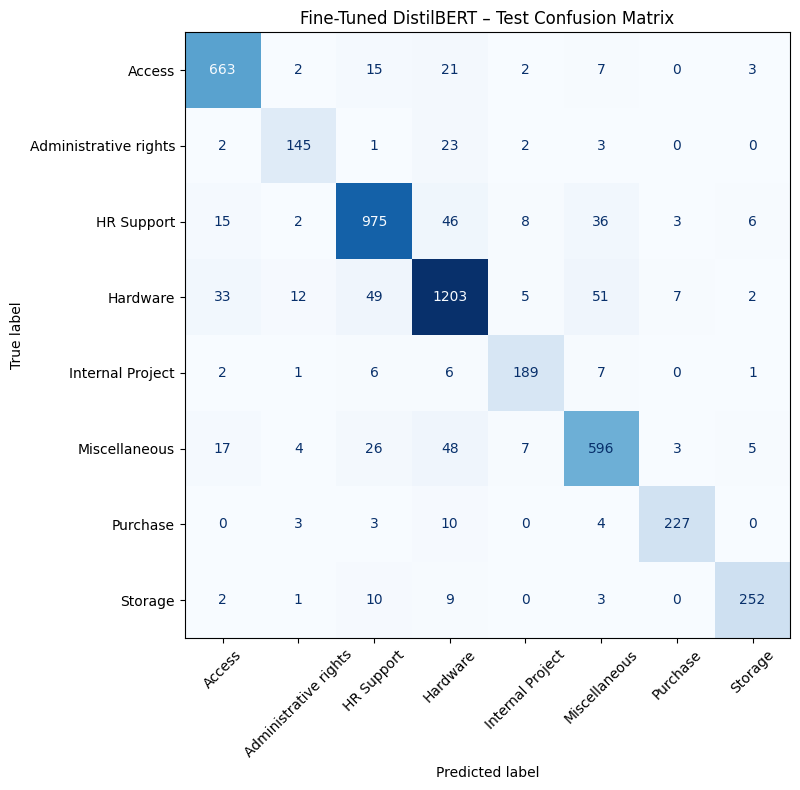


Final classification evaluation completed.
Results saved to: /content/drive/MyDrive/Cloud_IT_Support_Copilot/outputs/classification


In [6]:

# ============================================================
# FINAL CLASSIFICATION EVALUATION AND BASELINE COMPARISON
# ============================================================

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# 1. Load the saved best fine-tuned model
finetuned_model = AutoModelForSequenceClassification.from_pretrained(
    CLASSIFIER_MODEL_DIR
)

finetuned_model.to("cuda")
finetuned_model.eval()

# 2. Generate predictions on the held-out test dataset
print("Evaluating fine-tuned model on the test dataset...")

test_output = trainer.predict(
    training_datasets["test"]
)

finetuned_predictions = np.argmax(
    test_output.predictions,
    axis=-1
)

# 3. Calculate final metrics
finetuned_metrics = {
    "accuracy": accuracy_score(
        y_test, finetuned_predictions
    ),
    "macro_precision": precision_score(
        y_test, finetuned_predictions,
        average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        y_test, finetuned_predictions,
        average="macro", zero_division=0
    ),
    "macro_f1": f1_score(
        y_test, finetuned_predictions,
        average="macro", zero_division=0
    )
}

print("\nFINE-TUNED TEST RESULTS")
print("=" * 55)

for metric, value in finetuned_metrics.items():
    print(f"{metric}: {value:.4f}")

# 4. Per-category classification report
print("\nFINE-TUNED CLASSIFICATION REPORT")

report_dict = classification_report(
    y_test,
    finetuned_predictions,
    target_names=label_names,
    output_dict=True,
    zero_division=0
)

display(
    pd.DataFrame(report_dict).T.round(4)
)

# 5. Compare baseline and fine-tuned metrics
comparison = pd.DataFrame([
    {"Metric": metric, "Baseline": baseline_metrics[metric],
     "Fine-tuned": finetuned_metrics[metric],
     "Improvement (percentage points)": (
         finetuned_metrics[metric] - baseline_metrics[metric]
     ) * 100}
    for metric in baseline_metrics
])

print("\nBASELINE VS FINE-TUNED")
display(comparison.round(4))

# 6. Save final evaluation outputs
CLASSIFICATION_DIR = PROJECT_ROOT / "outputs/classification"

with open(
    CLASSIFICATION_DIR / "finetuned_results.json", "w"
) as file:
    json.dump(finetuned_metrics, file, indent=4)

np.save(
    CLASSIFICATION_DIR / "finetuned_predictions.npy",
    finetuned_predictions
)

comparison.to_csv(
    CLASSIFICATION_DIR / "baseline_vs_finetuned.csv",
    index=False
)

pd.DataFrame(report_dict).T.to_csv(
    CLASSIFICATION_DIR / "finetuned_classification_report.csv"
)

# 7. Generate and save confusion matrix
cm = confusion_matrix(
    y_test,
    finetuned_predictions
)

fig, ax = plt.subplots(figsize=(10, 8))

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_names
)

display_matrix.plot(
    ax=ax,
    xticks_rotation=45,
    cmap="Blues",
    colorbar=False
)

plt.title("Fine-Tuned DistilBERT – Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    CLASSIFICATION_DIR / "finetuned_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# 8. Release model resources
del finetuned_model
gc.collect()
torch.cuda.empty_cache()

print("\nFinal classification evaluation completed.")
print("Results saved to:", CLASSIFICATION_DIR)


## Fine-Tuning – Training and Validation Curves

Training loss (logged every 100 steps) and validation loss, accuracy and macro F1 (evaluated after each epoch) are read from the saved training history. They show how the model converged and whether validation performance diverged from training, which is the evidence for the checkpoint selected by validation macro F1.

In [ ]:
# ============================================================
# TRAINING / VALIDATION CURVES
# ============================================================
import json
import matplotlib.pyplot as plt
import pandas as pd

history_path = PROJECT_ROOT / "outputs/classification/training_history.json"

with open(history_path, "r") as file:
    history = json.load(file)

# Training-loss log entries contain "loss"; evaluation entries contain "eval_loss"
train_log = [h for h in history if "loss" in h and "eval_loss" not in h]
eval_log = [h for h in history if "eval_loss" in h]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: loss curves
axes[0].plot(
    [h["step"] for h in train_log],
    [h["loss"] for h in train_log],
    label="Training loss (every 100 steps)",
    alpha=0.8
)
axes[0].plot(
    [h["step"] for h in eval_log],
    [h["eval_loss"] for h in eval_log],
    marker="o",
    linewidth=2,
    label="Validation loss (each epoch)"
)
axes[0].set_xlabel("Training step")
axes[0].set_ylabel("Loss")
axes[0].set_title("Training vs validation loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Right: validation metrics per epoch
epochs = [h["epoch"] for h in eval_log]
axes[1].plot(epochs, [h["eval_accuracy"] for h in eval_log], marker="o", label="Validation accuracy")
axes[1].plot(epochs, [h["eval_macro_f1"] for h in eval_log], marker="s", label="Validation macro F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_title("Validation metrics per epoch")
axes[1].set_xticks(epochs)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

curves_path = PROJECT_ROOT / "outputs/classification/training_curves.png"
plt.savefig(curves_path, dpi=150, bbox_inches="tight")
plt.show()

# Per-epoch table
curve_table = pd.DataFrame([
    {
        "epoch": h["epoch"],
        "validation_loss": round(h["eval_loss"], 4),
        "validation_accuracy": round(h["eval_accuracy"], 4),
        "validation_macro_f1": round(h["eval_macro_f1"], 4)
    }
    for h in eval_log
])
display(curve_table)

# Factual observation on validation loss
val_losses = [h["eval_loss"] for h in eval_log]
if len(val_losses) >= 2 and val_losses[-1] > min(val_losses):
    print("\nValidation loss rose after its minimum while training loss kept falling, "
          "a sign of mild overfitting; the checkpoint with the best validation macro F1 was kept.")
else:
    print("\nValidation loss decreased through the final epoch, so no overfitting is visible within 3 epochs.")

print("Curves saved to:", curves_path)

## Ticket Summarisation Using Qwen2.5-3B-Instruct

The second NLP task generates concise, structured summaries of IT support tickets.

The project uses Qwen2.5-3B-Instruct with 4-bit NF4 quantisation to fit the model within the available GPU memory.

The summarisation prompt is designed to preserve the reported issue, relevant details, troubleshooting already performed and support action required. The model is instructed not to invent missing information or introduce unsupported causes, dates or actions.

The summaries are reviewed qualitatively because the source dataset does not contain reference summaries.

In [7]:

# ============================================================
# TICKET SUMMARISATION: LOAD MODEL AND DEFINE FINAL FUNCTION
# ============================================================

from transformers import (
    AutoTokenizer as AutoTokenizerForGeneration,
    AutoModelForCausalLM,
    BitsAndBytesConfig
)

GENERATOR_MODEL_NAME = "Qwen/Qwen2.5-3B-Instruct"

# 1. Configure 4-bit quantisation
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

# 2. Load tokenizer
generator_tokenizer = AutoTokenizerForGeneration.from_pretrained(
    GENERATOR_MODEL_NAME
)

# 3. Load quantised language model
generator_model = AutoModelForCausalLM.from_pretrained(
    GENERATOR_MODEL_NAME,
    quantization_config=quantization_config,
    device_map="auto"
)

generator_model.eval()

print("Summarisation model loaded successfully.")
print("Model:", GENERATOR_MODEL_NAME)
print("Device:", next(generator_model.parameters()).device)

# 4. Define the final structured summarisation function
def summarise_ticket(ticket_text, max_new_tokens=220):

    if not isinstance(ticket_text, str) or not ticket_text.strip():
        return "Please provide a valid ticket description."

    system_prompt = """
You are an IT support ticket summarisation assistant.

Summarise the supplied ticket accurately and concisely.

Use exactly these four sections:

Reported Issue:
Relevant Details:
Troubleshooting Performed:
Support Action Required:

Instructions:
- Use only information explicitly stated in the ticket.
- Do not invent dates, causes, technical steps, actions or business impact.
- Preserve important names, systems and error details when provided.
- If information is missing, write "Not specified".
- Do not present assumptions as facts.
- Keep the summary concise and professional.
"""

    messages = [
        {"role": "system", "content": system_prompt},
        {
            "role": "user",
            "content": f"Summarise this support ticket:\n\n{ticket_text}"
        }
    ]

    prompt = generator_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = generator_tokenizer(
        prompt,
        return_tensors="pt"
    ).to(generator_model.device)

    with torch.no_grad():
        output = generator_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            repetition_penalty=1.05,
            pad_token_id=generator_tokenizer.eos_token_id
        )

    generated_tokens = output[0][inputs["input_ids"].shape[1]:]

    summary = generator_tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()

    return summary

print("\nFinal ticket summarisation function is ready.")


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Summarisation model loaded successfully.
Model: Qwen/Qwen2.5-3B-Instruct
Device: cuda:0

Final ticket summarisation function is ready.


## Ticket Summarisation – Demonstration and Evaluation

The summarisation model is tested using five representative tickets selected from the labelled dataset.

The generated summaries are reviewed qualitatively for factual accuracy, completeness and preservation of relevant troubleshooting details. As the dataset does not contain reference summaries, this evaluation is qualitative rather than based on automated summary metrics.

In [8]:

# ============================================================
# SUMMARISATION DEMONSTRATION – REPRESENTATIVE TICKETS
# ============================================================

# Calculate ticket lengths
summary_candidates = tickets_df.copy()

summary_candidates["word_count"] = (
    summary_candidates["Document"].str.split().str.len()
)

# Select one representative ticket per category:
# choose the ticket closest to the category's median length
representative_tickets = []

for category in label_names:

    category_df = summary_candidates[
        summary_candidates["Topic_group"] == category
    ].copy()

    median_length = category_df["word_count"].median()

    # Prefer tickets with enough information to summarise
    suitable_tickets = category_df[
        (category_df["word_count"] >= 20) &
        (category_df["word_count"] <= 150)
    ].copy()

    if suitable_tickets.empty:
        suitable_tickets = category_df.copy()

    suitable_tickets["median_distance"] = (
        suitable_tickets["word_count"] - median_length
    ).abs()

    selected_ticket = suitable_tickets.sort_values(
        "median_distance"
    ).iloc[0]

    representative_tickets.append(selected_ticket)

summary_samples = pd.DataFrame(representative_tickets)

# Generate summaries
summary_results = []

for _, ticket in summary_samples.iterrows():

    print("\n" + "=" * 75)
    print("CATEGORY:", ticket["Topic_group"])
    print("TICKET LENGTH:", int(ticket["word_count"]), "words")

    print("\nORIGINAL TICKET:")
    print(ticket["Document"])

    print("\nGENERATED SUMMARY:")
    summary = summarise_ticket(ticket["Document"])
    print(summary)

    summary_results.append({
        "category": ticket["Topic_group"],
        "word_count": int(ticket["word_count"]),
        "original_ticket": ticket["Document"],
        "generated_summary": summary
    })

# Save the corrected results
SUMMARY_DIR = PROJECT_ROOT / "outputs/summarisation"

with open(
    SUMMARY_DIR / "final_summaries.json",
    "w"
) as file:
    json.dump(summary_results, file, indent=4)

pd.DataFrame(summary_results).to_csv(
    SUMMARY_DIR / "final_summaries.csv",
    index=False
)

print("\n" + "=" * 75)
print("Summarisation demonstration completed.")
print("Representative tickets processed:", len(summary_results))
print("Categories:", len(set(x["category"] for x in summary_results)))
print("Results saved to:", SUMMARY_DIR)



CATEGORY: Access
TICKET LENGTH: 22 words

ORIGINAL TICKET:
locked sent friday locked hi there upon trying get access portal locked out could you please unlock for password thanks digital manager

GENERATED SUMMARY:
Reported Issue: Unable to access a portal due to being locked out.
Relevant Details: User is a Digital Manager who tried to log in Friday but was locked out. They need the portal unlocked with their password.
Troubling Performed: Not specified.
Support Action Required: Unlock the user's account using their password.

CATEGORY: Administrative rights
TICKET LENGTH: 30 words

ORIGINAL TICKET:
mobile data problems mobile data problems hi have having problems trying connect mobile data when out about can only use moment bit annoying any you could help with please thanks

GENERATED SUMMARY:
Reported Issue: Having problems connecting mobile data when out of range; can only use 3G/2G (Moment) which is annoying.
Relevant Details: Not specified
Troubleshooting Performed: Not specifie

## Retrieval-Augmented Generation (RAG) – Knowledge Base Preparation

This section implements a Retrieval-Augmented Generation (RAG) pipeline for technical support. A collection of Microsoft and Windows support documentation is used as the knowledge base.

The documents are extracted, cleaned and divided into smaller text chunks. These chunks will subsequently be converted into vector embeddings and stored in a FAISS index, enabling semantic retrieval of relevant troubleshooting information in response to user questions.

The corpus contains **16** documents. A 17th planned source (*Manage user accounts in Windows*) returned HTTP 404 and was excluded. Chunks are kept to 150 words (30-word overlap) so that each chunk fits inside the embedding model's 256-token input limit and is embedded in full.

In [ ]:
import requests
import json
import re
import time
from bs4 import BeautifulSoup

# 16-document support corpus.
# A 17th planned source ("Manage user accounts in Windows") returned HTTP 404
# and was removed from this list, so 16 documents are collected.
documents = [
    {
        "document_id": "outlook_search",
        "title": "Troubleshooting Outlook search issues",
        "url": "https://support.microsoft.com/en-us/outlook/troubleshooting-outlook-search-issues"
    },
    {
        "document_id": "sharepoint_sync",
        "title": "Fix SharePoint Online sync problems",
        "url": "https://support.microsoft.com/en-us/sharepoint/sync/fix-sharepoint-online-sync-problems"
    },
    {
        "document_id": "onedrive_errors",
        "title": "What do the OneDrive error codes mean?",
        "url": "https://support.microsoft.com/en-us/onedrive/what-do-the-onedrive-error-codes-mean"
    },
    {
        "document_id": "onedrive_signin",
        "title": "Can't sign in to OneDrive",
        "url": "https://support.microsoft.com/en-us/onedrive/can-t-sign-in-to-onedrive"
    },
    {
        "document_id": "edge_signin",
        "title": "Troubleshoot Microsoft Edge sign-in problems",
        "url": "https://learn.microsoft.com/en-us/troubleshoot/microsoft-edge/security/troubleshoot-sign-in-issues"
    },
    {
        "document_id": "local_password",
        "title": "Change or reset your local account password in Windows",
        "url": "https://support.microsoft.com/en-us/windows/security/change-or-reset-your-local-account-password-in-windows"
    },
    {
        "document_id": "microsoft_password",
        "title": "Change or reset your Microsoft account password",
        "url": "https://support.microsoft.com/en-gb/accounts-billing/security/change-or-reset-your-microsoft-account-password-in-windows"
    },
    {
        "document_id": "windows_signin",
        "title": "Troubleshoot problems signing in to Windows",
        "url": "https://support.microsoft.com/en-us/windows/security/identity-signin/troubleshoot-problems-signing-in-to-windows"
    },
    {
        "document_id": "bitlocker_key",
        "title": "Find your BitLocker recovery key",
        "url": "https://support.microsoft.com/en-gb/windows/security/encryption/find-your-bitlocker-recovery-key"
    },
    {
        "document_id": "bitlocker_process",
        "title": "BitLocker recovery process",
        "url": "https://learn.microsoft.com/en-us/windows/security/operating-system-security/data-protection/bitlocker/recovery-process"
    },
    {
        "document_id": "bitlocker_overview",
        "title": "BitLocker recovery overview",
        "url": "https://learn.microsoft.com/en-us/windows/security/operating-system-security/data-protection/bitlocker/recovery-overview"
    },
    {
        "document_id": "printer_troubleshooting",
        "title": "Fix printer connection and printing problems in Windows",
        "url": "https://support.microsoft.com/en-us/windows/hardware/printer/fix-printer-connection-and-printing-problems-in-windows"
    },
    {
        "document_id": "printer_drivers",
        "title": "Fix printer driver compatibility issues in Windows",
        "url": "https://support.microsoft.com/en-us/windows/hardware/printer/fix-printer-driver-compatibility-issues-in-windows"
    },
    {
        "document_id": "device_drivers",
        "title": "Update drivers through Device Manager in Windows",
        "url": "https://support.microsoft.com/en-au/windows/update-drivers-through-device-manager-in-windows-ec62f46c-ff14-c91d-eead-d7126dc1f7b6"
    },
    {
        "document_id": "disk_space",
        "title": "Free up drive space in Windows",
        "url": "https://support.microsoft.com/en-us/windows/experience/storage-filemanagement/free-up-drive-space-in-windows"
    },
    {
        "document_id": "windows_update",
        "title": "Troubleshoot problems updating Windows",
        "url": "https://support.microsoft.com/en-us/windows/deployment/updates-lifecycle/troubleshoot-problems-updating-windows"
    }
]

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/120 Safari/537.36"
}

collected_documents = []
failed_documents = []

for i, doc in enumerate(documents, start=1):
    print(f"[{i}/{len(documents)}] Collecting: {doc['title']}")

    try:
        response = requests.get(
            doc["url"],
            headers=headers,
            timeout=40
        )
        response.raise_for_status()

        soup = BeautifulSoup(response.text, "html.parser")

        # Remove irrelevant page elements
        for element in soup(["script", "style", "nav", "footer", "header"]):
            element.decompose()

        # Extract the main article content
        main_content = (
            soup.find("main")
            or soup.find("article")
            or soup.body
            or soup
        )

        text_content = main_content.get_text(separator=" ", strip=True)
        text_content = re.sub(r"\s+", " ", text_content).strip()

        word_count = len(text_content.split())

        if word_count < 100:
            raise ValueError(
                f"Extracted only {word_count} words; article may not have loaded correctly."
            )

        collected_documents.append({
            "document_id": doc["document_id"],
            "title": doc["title"],
            "url": doc["url"],
            "text": text_content,
            "word_count": word_count
        })

        print(f"    Success: {word_count:,} words")

    except Exception as e:
        failed_documents.append({
            "document_id": doc["document_id"],
            "title": doc["title"],
            "url": doc["url"],
            "error": str(e)
        })

        print(f"    Failed: {e}")

    time.sleep(1)

# Save complete document collection
raw_docs_path = PROJECT_ROOT / "corpus" / "raw" / "support_documents.json"

with open(raw_docs_path, "w", encoding="utf-8") as f:
    json.dump(collected_documents, f, indent=2, ensure_ascii=False)

# Save collection metadata
collection_metadata = {
    "documents_attempted": len(documents),
    "documents_collected": len(collected_documents),
    "documents_failed": len(failed_documents),
    "total_words": sum(d["word_count"] for d in collected_documents),
    "failed_documents": failed_documents
}

metadata_path = PROJECT_ROOT / "metadata" / "document_collection_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(collection_metadata, f, indent=2, ensure_ascii=False)

# Display results
print("\n" + "=" * 65)
print("COMPLETE SUPPORT CORPUS SUMMARY")
print("=" * 65)

print(f"Documents attempted: {len(documents)}")
print(f"Documents collected: {len(collected_documents)}")
print(f"Documents failed: {len(failed_documents)}")
print(f"Total extracted words: {collection_metadata['total_words']:,}")

print("\nCOLLECTED DOCUMENTS")
print("-" * 65)

for doc in collected_documents:
    print(f"{doc['title']}: {doc['word_count']:,} words")

if failed_documents:
    print("\nDOCUMENTS THAT COULD NOT BE COLLECTED")
    print("-" * 65)

    for doc in failed_documents:
        print(f"{doc['title']}: {doc['error']}")

print(f"\nDocuments saved to: {raw_docs_path}")
print(f"Metadata saved to: {metadata_path}")

In [ ]:
import json

# Load the complete collected corpus
raw_docs_path = PROJECT_ROOT / "corpus" / "raw" / "support_documents.json"

with open(raw_docs_path, "r", encoding="utf-8") as f:
    collected_documents = json.load(f)

CHUNK_SIZE = 150   # words; keeps each chunk within the 256-token embedding limit
CHUNK_OVERLAP = 30
CHUNK_STEP = CHUNK_SIZE - CHUNK_OVERLAP

document_chunks = []

for doc in collected_documents:
    words = doc["text"].split()
    chunk_number = 0

    for start in range(0, len(words), CHUNK_STEP):
        chunk_words = words[start:start + CHUNK_SIZE]

        if len(chunk_words) < 40:
            continue

        document_chunks.append({
            "chunk_id": f"{doc['document_id']}_chunk_{chunk_number}",
            "document_id": doc["document_id"],
            "title": doc["title"],
            "source_url": doc["url"],
            "chunk_number": chunk_number,
            "text": " ".join(chunk_words),
            "word_count": len(chunk_words)
        })

        chunk_number += 1

# Save the chunks
chunks_path = PROJECT_ROOT / "rag" / "chunks" / "document_chunks.json"

with open(chunks_path, "w", encoding="utf-8") as f:
    json.dump(document_chunks, f, indent=2, ensure_ascii=False)

# Display chunking results
print("DOCUMENT CHUNKING SUMMARY")
print("=" * 60)
print(f"Documents processed: {len(collected_documents)}")
print(f"Total source words: {sum(doc['word_count'] for doc in collected_documents):,}")
print(f"Chunk size: {CHUNK_SIZE} words")
print(f"Chunk overlap: {CHUNK_OVERLAP} words")
print(f"Total chunks created: {len(document_chunks)}")
print(f"Saved to: {chunks_path}")

print("\nSAMPLE CHUNK")
print("=" * 60)
print(f"Title: {document_chunks[0]['title']}")
print(f"Chunk ID: {document_chunks[0]['chunk_id']}")
print(f"Word count: {document_chunks[0]['word_count']}")
print(f"Text preview:\n{document_chunks[0]['text'][:500]}...")

In [ ]:
import json
import time
import numpy as np
import faiss
from sentence_transformers import SentenceTransformer

# Load document chunks
chunks_path = PROJECT_ROOT / "rag" / "chunks" / "document_chunks.json"

with open(chunks_path, "r", encoding="utf-8") as f:
    document_chunks = json.load(f)

# Load embedding model
EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"

embedding_model = SentenceTransformer(
    EMBEDDING_MODEL_NAME,
    device="cuda"
)

# Prepare chunk texts
chunk_texts = [chunk["text"] for chunk in document_chunks]

# Make the embedding input limit explicit and verify that no chunk is truncated
embedding_model.max_seq_length = 256
token_lengths = [
    len(ids) for ids in embedding_model.tokenizer(
        chunk_texts, add_special_tokens=True, truncation=False
    )["input_ids"]
]
n_truncated = sum(length > embedding_model.max_seq_length for length in token_lengths)

print("EMBEDDING INPUT-LENGTH CHECK")
print("Embedding max_seq_length:", embedding_model.max_seq_length, "tokens")
print("Chunk length in tokens - mean:", round(float(np.mean(token_lengths)), 1),
      "| max:", max(token_lengths))
print(f"Chunks longer than the limit: {n_truncated} of {len(token_lengths)}")
if n_truncated:
    print("WARNING: some chunks are truncated at embedding time. Reduce CHUNK_SIZE in the chunking cell and re-run.")
print()

# Generate embeddings
start_time = time.time()

document_embeddings = embedding_model.encode(
    chunk_texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

document_embeddings = document_embeddings.astype("float32")

# Build FAISS index using cosine similarity
embedding_dimension = document_embeddings.shape[1]

faiss_index = faiss.IndexFlatIP(embedding_dimension)
faiss_index.add(document_embeddings)

# Save embeddings
embeddings_path = PROJECT_ROOT / "rag" / "embeddings" / "document_embeddings.npy"
np.save(embeddings_path, document_embeddings)

# Save FAISS index
index_path = PROJECT_ROOT / "rag" / "index" / "support_documents.index"
faiss.write_index(faiss_index, str(index_path))

# Save chunk metadata
metadata = [
    {
        key: chunk[key]
        for key in [
            "chunk_id",
            "document_id",
            "title",
            "source_url",
            "chunk_number"
        ]
    }
    for chunk in document_chunks
]

metadata_path = PROJECT_ROOT / "rag" / "index" / "chunk_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

elapsed_time = time.time() - start_time

print("=" * 60)
print("FAISS KNOWLEDGE BASE CREATED")
print("=" * 60)
print(f"Embedding model: {EMBEDDING_MODEL_NAME}")
print(f"Documents: {len(set(c['document_id'] for c in document_chunks))}")
print(f"Chunks indexed: {faiss_index.ntotal}")
print(f"Embedding dimensions: {embedding_dimension}")
print(f"Embedding matrix shape: {document_embeddings.shape}")
print(f"Index build time: {elapsed_time:.2f} seconds")
print("\nSaved files:")
print(f"FAISS index: {index_path}")
print(f"Embeddings: {embeddings_path}")
print(f"Chunk metadata: {metadata_path}")

## RAG – Testing Document Retrieval

Test the FAISS vector index using representative IT support questions.
For each query, retrieve the four most relevant document chunks and inspect
their titles and similarity scores to assess retrieval quality.

In [ ]:
import json
import faiss
import numpy as np

# Load the saved FAISS index and metadata
index_path = PROJECT_ROOT / "rag" / "index" / "support_documents.index"
metadata_path = PROJECT_ROOT / "rag" / "index" / "chunk_metadata.json"

faiss_index = faiss.read_index(str(index_path))

with open(metadata_path, "r", encoding="utf-8") as f:
    chunk_metadata = json.load(f)

# Retrieve the most relevant chunks for a query
def retrieve_documents(query, top_k=4):
    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    scores, indices = faiss_index.search(query_embedding, top_k)

    retrieved = []

    for score, idx in zip(scores[0], indices[0]):
        if idx == -1:
            continue

        result = chunk_metadata[idx].copy()
        result["text"] = document_chunks[idx]["text"]
        result["similarity_score"] = float(score)

        retrieved.append(result)

    return retrieved


# Representative IT support queries
retrieval_test_queries = [
    "How can I reset my Windows account password?",
    "My printer is not printing. How can I troubleshoot it?",
    "OneDrive is not syncing my files. How can I fix this?",
    "How do I recover my computer using a BitLocker recovery key?",
    "My Windows computer is running out of disk space. How can I free up space?",
    "Windows Update is failing to install updates. What should I do?"
]

# Run retrieval tests
retrieval_test_results = []

for query in retrieval_test_queries:
    results = retrieve_documents(query, top_k=4)

    print("\n" + "=" * 80)
    print(f"QUERY: {query}")
    print("=" * 80)

    for rank, result in enumerate(results, start=1):
        print(
            f"\nRank {rank}: {result['title']}"
            f"\nSimilarity: {result['similarity_score']:.4f}"
            f"\nSource: {result['source_url']}"
        )

        retrieval_test_results.append({
            "query": query,
            "rank": rank,
            "title": result["title"],
            "similarity_score": result["similarity_score"],
            "source_url": result["source_url"]
        })

# Save retrieval test results
results_path = PROJECT_ROOT / "outputs" / "rag" / "retrieval_test_results.json"

with open(results_path, "w", encoding="utf-8") as f:
    json.dump(retrieval_test_results, f, indent=2, ensure_ascii=False)

print("\n" + "=" * 80)
print(f"Retrieval results saved to: {results_path}")

## RAG – Context-Grounded Support Answer Generation

Combine semantic retrieval with the Qwen2.5-3B-Instruct language model.

For each IT support question:
1. Retrieve the five most relevant knowledge-base chunks using FAISS and keep only those above a similarity threshold.
2. Pass the retrieved passages to the language model as context.
3. Generate a concise troubleshooting response grounded in that context.
4. Include the source documents so users can verify the guidance.

The model is instructed to avoid unsupported recommendations and acknowledge when the retrieved documentation does not contain sufficient information. If no chunk meets the similarity threshold, the language model is not called and the assistant returns an "insufficient documentation, please escalate" message instead.

In [ ]:
# Minimum cosine similarity of a chunk for it to be used as context.
# Starting value chosen from observed scores (irrelevant ticket ~0.27, relevant tickets >= 0.5);
# tune it with the threshold audit cell in the Situated Learning section.
SIMILARITY_THRESHOLD = 0.45

INSUFFICIENT_DOCS_MESSAGE = (
    "The available documentation does not provide sufficient guidance for this request. "
    "Please escalate this ticket to a human IT support agent."
)


def rag_answer(question, top_k=5, max_new_tokens=250, min_similarity=None):

    # Retrieve relevant knowledge-base chunks
    all_retrieved = retrieve_documents(question, top_k=top_k)
    threshold = SIMILARITY_THRESHOLD if min_similarity is None else min_similarity

    # Keep only chunks that are similar enough to the question
    retrieved_docs = [
        doc for doc in all_retrieved
        if doc["similarity_score"] >= threshold
    ]

    # Guard: if nothing is relevant enough, do not let the model improvise an answer
    if not retrieved_docs:
        return {
            "question": question,
            "answer": INSUFFICIENT_DOCS_MESSAGE,
            "sources": [],
            "retrieved_chunks": all_retrieved,
            "insufficient": True
        }

    # Build context from retrieved documents
    context_parts = []

    for i, doc in enumerate(retrieved_docs, start=1):
        context_parts.append(
            f"[Source {i}: {doc['title']}]\n{doc['text']}"
        )

    context = "\n\n".join(context_parts)

    # Conservative, grounding-focused system prompt
    system_prompt = """
You are an IT support assistant helping users troubleshoot
common workplace technology problems.

STRICT KNOWLEDGE-BASE GROUNDING RULES:

1. Use ONLY the information explicitly supported by the
   supplied knowledge-base passages.

2. Never invent or assume troubleshooting steps, commands,
   URLs, causes, settings, or solutions.

3. If the supplied passages do not contain enough information
   to answer a question, clearly state that the available
   documentation does not provide sufficient guidance.

4. Do not combine procedures for different products,
   operating systems, or account types.

5. Pay particular attention to distinctions between:
   - Windows and macOS
   - Microsoft accounts and local Windows accounts
   - Personal and work/school accounts
   - OneDrive and SharePoint

6. Do not recommend destructive, security-sensitive, or
   potentially disruptive actions unless the supplied
   documentation explicitly supports them.

7. Do not fabricate URLs or refer users to web pages that
   are not present in the supplied context.

RESPONSE FORMAT:

- Briefly acknowledge the reported problem.
- Provide only the troubleshooting steps supported by
  the retrieved documentation.
- Use numbered steps where appropriate.
- Keep the response concise and easy to follow.
- Clearly identify when additional IT support is needed.
- Do not claim that any action has been performed.

The response must be labelled:

"AI-generated summary, not a verified procedure."
"""

    user_prompt = f"""
Knowledge-base context:

{context}

User question:
{question}

Provide a concise troubleshooting response following
all the instructions above.
"""

    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_prompt}
    ]

    prompt = generator_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = generator_tokenizer(
        prompt,
        return_tensors="pt"
    ).to(generator_model.device)

    outputs = generator_model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        repetition_penalty=1.05,
        pad_token_id=generator_tokenizer.eos_token_id
    )

    generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

    answer = generator_tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()

    # Deduplicate source documents
    sources = []
    seen_urls = set()

    for doc in retrieved_docs:
        if doc["source_url"] not in seen_urls:
            sources.append({
                "title": doc["title"],
                "source_url": doc["source_url"],
                "similarity_score": doc["similarity_score"]
            })
            seen_urls.add(doc["source_url"])

    return {
        "question": question,
        "answer": answer,
        "sources": sources,
        "retrieved_chunks": all_retrieved,
        "insufficient": False
    }


print("RAG answer-generation function ready "
      f"(similarity threshold = {SIMILARITY_THRESHOLD}).")

## RAG – Answer Generation Demonstration and Evaluation

Evaluate the RAG assistant using representative IT support questions.

Inspect whether the generated responses:
- Address the user's question.
- Provide actionable troubleshooting steps.
- Stay grounded in the retrieved knowledge-base documents.
- Identify relevant source documents.

In [ ]:
import json
from IPython.display import display, Markdown

rag_test_questions = [
    "I forgot my Windows password. How can I reset it?",
    "My printer is connected but nothing prints. What should I do?",
    "OneDrive is not syncing files on my computer. How can I troubleshoot this?",
    "My computer is asking for a BitLocker recovery key. How do I recover access?",
    "My Windows laptop is running out of storage space. How can I free up space?",
    "Windows Update keeps failing. What troubleshooting steps should I try?"
]

rag_test_results = []

for question in rag_test_questions:
    result = rag_answer(question, top_k=5)

    rag_test_results.append({
        "question": result["question"],
        "answer": result["answer"],
        "sources": result["sources"]
    })

    display(Markdown(f"## Question\n{result['question']}"))
    display(Markdown(f"### Generated answer\n{result['answer']}"))

    display(Markdown("### Retrieved sources"))

    for source in result["sources"]:
        print(
            f"- {source['title']} "
            f"(similarity: {source['similarity_score']:.4f})"
        )
        print(f"  {source['source_url']}")

# Save generated answers and source references
rag_evaluation_path = (
    PROJECT_ROOT / "outputs" / "rag" / "rag_answer_evaluation.json"
)

with open(rag_evaluation_path, "w", encoding="utf-8") as f:
    json.dump(rag_test_results, f, indent=2, ensure_ascii=False)

print("\n" + "=" * 70)
print("RAG ANSWER GENERATION TEST COMPLETED")
print(f"Questions evaluated: {len(rag_test_results)}")
print(f"Results saved to: {rag_evaluation_path}")

## Integrated Cloud & IT Support Copilot – Gradio Application

Create an interactive application that combines the three NLP capabilities developed in this assignment.

The application will allow a user to enter an IT support ticket and:
- Predict its support category using the fine-tuned DistilBERT classifier.
- Generate a structured summary using Qwen2.5-3B-Instruct.
- Retrieve relevant knowledge-base passages and generate a troubleshooting response using RAG.
- Answer free-form support questions in a separate RAG chatbot tab.

Gradio provides the interface for demonstrating the integrated application.

In [15]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Reload fine-tuned classification model
CLASSIFIER_MODEL_PATH = str(
    PROJECT_ROOT / "models" / "classifier" / "finetuned"
)

classifier_tokenizer = AutoTokenizer.from_pretrained(
    CLASSIFIER_MODEL_PATH
)

classifier_model = AutoModelForSequenceClassification.from_pretrained(
    CLASSIFIER_MODEL_PATH
)

classifier_model.eval()
classifier_model.to("cuda" if torch.cuda.is_available() else "cpu")

print("Classification model loaded successfully.")
print(f"Model device: {next(classifier_model.parameters()).device}")
print(f"Number of categories: {classifier_model.config.num_labels}")
print(f"Categories: {list(classifier_model.config.id2label.values())}")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Classification model loaded successfully.
Model device: cuda:0
Number of categories: 8
Categories: ['Access', 'Administrative rights', 'HR Support', 'Hardware', 'Internal Project', 'Miscellaneous', 'Purchase', 'Storage']


## Integrated Application – Preparing the AI Capabilities

Prepare three functions for the interactive application:

1. **Ticket Classification:** Predict the support category and confidence score using fine-tuned DistilBERT.
2. **Ticket Summarisation:** Generate a structured summary using Qwen2.5-3B-Instruct.
3. **Knowledge-Based Support:** Generate a troubleshooting response using RAG, and return retrieved evidence and source references.

These functions will be connected to the Gradio interface in the next section.

In [ ]:
import torch
import numpy as np

# --------------------------------------------------
# 1. Ticket Classification
# --------------------------------------------------

def app_classify(ticket_text):

    if not ticket_text or not ticket_text.strip():
        return "Please enter a support ticket."

    device = next(classifier_model.parameters()).device

    inputs = classifier_tokenizer(
        ticket_text,
        return_tensors="pt",
        truncation=True,
        max_length=256,
        padding=True
    ).to(device)

    with torch.no_grad():
        outputs = classifier_model(**inputs)

    probabilities = torch.softmax(outputs.logits, dim=-1)[0]

    predicted_id = int(torch.argmax(probabilities).item())
    predicted_category = classifier_model.config.id2label[predicted_id]
    confidence = float(probabilities[predicted_id].item())

    # Display category probabilities
    sorted_indices = torch.argsort(
        probabilities,
        descending=True
    )

    result = [
        "### Predicted Ticket Category",
        f"**{predicted_category}**",
        f"Confidence: **{confidence:.2%}**",
        "",
        "### Category Probabilities"
    ]

    for idx in sorted_indices:
        category = classifier_model.config.id2label[int(idx)]
        probability = float(probabilities[idx].item())

        result.append(f"- {category}: {probability:.2%}")

    return "\n".join(result)


# --------------------------------------------------
# 2. Ticket Summarisation
# --------------------------------------------------

def app_summarise(ticket_text):

    if not ticket_text or not ticket_text.strip():
        return "Please enter a support ticket."

    return summarise_ticket(ticket_text)


# --------------------------------------------------
# 3. RAG-Based Support Assistant
# --------------------------------------------------

def app_support_assistant(question):

    if not question or not question.strip():
        return "Please enter a support question.", "", ""

    result = rag_answer(question, top_k=5, max_new_tokens=300)

    # Format retrieved evidence (all retrieved chunks; flag those below the threshold)
    evidence_parts = []

    for i, doc in enumerate(result["retrieved_chunks"], start=1):
        flag = (
            ""
            if doc["similarity_score"] >= SIMILARITY_THRESHOLD
            else " (below similarity threshold - not used)"
        )
        evidence_parts.append(
            f"### Evidence {i}: {doc['title']}{flag}\n"
            f"Similarity: {doc['similarity_score']:.4f}\n\n"
            f"{doc['text'][:1200]}"
        )

    evidence_output = "\n\n---\n\n".join(evidence_parts)

    # Format source references
    if result["sources"]:
        source_output = "\n".join(
            f"- [{source['title']}]({source['source_url']})"
            for source in result["sources"]
        )
    else:
        source_output = (
            "No knowledge-base document met the similarity threshold "
            f"({SIMILARITY_THRESHOLD:.2f})."
        )

    disclaimer = (
        "\n\n**AI-generated guidance; verify the steps against "
        "the linked support documentation.**"
    )

    if result.get("insufficient"):
        answer_output = "**" + result["answer"] + "**"
    else:
        answer_output = result["answer"] + disclaimer

    return answer_output, evidence_output, source_output


print("All three application functions defined successfully.")


In [ ]:
import gradio as gr

def process_ticket(ticket_text, progress=gr.Progress()):

    # The click handler has 6 output components, so every branch returns 6 values:
    # (classification, summary, rag answer, evidence, sources, status)
    if not ticket_text or not ticket_text.strip():
        return (
            "Please enter a support ticket.",
            "",
            "",
            "",
            "",
            "Please enter a ticket to begin."
        )

    # Task 1: Classification
    progress(0.10, desc="Classifying support ticket...")
    classification_result = app_classify(ticket_text)

    progress(0.33, desc="Ticket classification completed")

    # Task 2: Summarisation
    progress(0.40, desc="Generating ticket summary...")
    summary_result = app_summarise(ticket_text)

    progress(0.66, desc="Ticket summarisation completed")

    # Task 3: RAG support assistance
    progress(0.72, desc="Retrieving knowledge-base evidence and generating support guidance...")
    rag_answer_result, evidence_result, sources_result = (
        app_support_assistant(ticket_text)
    )

    progress(1.0, desc="All three tasks completed!")

    status = "All three analysis tasks completed successfully."

    return (
        classification_result,
        summary_result,
        rag_answer_result,
        evidence_result,
        sources_result,
        status
    )


print("Integrated analysis function defined successfully.")


## RAG Support Chatbot

A dedicated chatbot lets a user ask free-form IT support questions and receive answers grounded in the knowledge base. Each reply lists its source documents, and short follow-up questions (for example "what if that doesn't work?") are combined with the previous question for retrieval, so the conversation can continue across turns. When no document is similar enough, the chatbot says the documentation is insufficient instead of guessing.

In [ ]:
# ============================================================
# RAG CHATBOT FUNCTION
# ============================================================

def _previous_user_turns(history):
    """Return earlier user messages from a Gradio chat history (messages or tuples format)."""
    turns = []
    for item in history or []:
        if isinstance(item, dict):
            if item.get("role") == "user":
                content = item.get("content")
                turns.append(content if isinstance(content, str) else str(content))
        elif isinstance(item, (list, tuple)) and item and isinstance(item[0], str):
            turns.append(item[0])
    return turns


def chat_with_knowledge_base(message, history):

    if not message or not message.strip():
        return "Please enter a support question."

    # Short follow-ups are combined with the previous question so retrieval has context
    previous_turns = _previous_user_turns(history)
    query = message
    if previous_turns and len(message.split()) < 8:
        query = previous_turns[-1] + " " + message

    result = rag_answer(query, top_k=5, max_new_tokens=300)

    if result.get("insufficient"):
        return f"**{result['answer']}**"

    sources = "\n".join(
        f"- [{source['title']}]({source['source_url']})"
        for source in result["sources"]
    )

    return (
        f"{result['answer']}\n\n"
        f"**Sources**\n{sources}\n\n"
        "*AI-generated guidance; verify the steps against the linked documentation.*"
    )


print("RAG chatbot function defined successfully.")

## Integrated Application – Gradio User Interface

Build the interactive Cloud & IT Support Copilot interface.

The interface includes:
- A support-ticket input area.
- An Analyse Ticket button.
- A live progress indicator while the three AI tasks execute.
- A status message indicating completion.
- Separate tabs for classification, summarisation and RAG-based support guidance.
- Retrieved knowledge-base evidence and source references.
- Example tickets, and a separate **Support Chatbot** tab for free-form questions.

In [ ]:
import gradio as gr

with gr.Blocks(title="Cloud & IT Support Copilot") as demo:

    gr.Markdown(
        """
        # Cloud & IT Support Copilot

        An AI-powered assistant for IT support teams.

        Analyse a support ticket (classification, summary and knowledge-base guidance),
        or ask the support chatbot a question directly.
        """
    )

    with gr.Tabs():

        # ---------------- Ticket analysis ----------------
        with gr.Tab("Ticket Analysis"):

            with gr.Row():
                with gr.Column(scale=1):

                    ticket_input = gr.Textbox(
                        label="IT Support Ticket",
                        placeholder="Describe the user's IT issue here...",
                        lines=8
                    )

                    analyze_button = gr.Button(
                        "Analyse Ticket",
                        variant="primary"
                    )

                    gr.Examples(
                        examples=[
                            ["I forgot my Windows password and I am locked out of my laptop. I need to get back in before a client meeting this afternoon."],
                            ["OneDrive has stopped syncing my project folders since yesterday and shows a sync error. I have already restarted my laptop."],
                            ["I cannot submit a purchase request in the procurement portal. It shows an error when I press submit."]
                        ],
                        inputs=ticket_input,
                        label="Example tickets"
                    )

                    status_output = gr.Markdown(
                        "Ready. Enter a ticket and select **Analyse Ticket**."
                    )

            with gr.Tabs():

                with gr.Tab("Ticket Classification"):
                    classification_output = gr.Markdown(
                        label="Predicted Category"
                    )

                with gr.Tab("Ticket Summarisation"):
                    summary_output = gr.Markdown(
                        label="Ticket Summary"
                    )

                with gr.Tab("Support Assistant"):
                    rag_output = gr.Markdown(
                        label="Generated Troubleshooting Guidance"
                    )

                    with gr.Accordion("Retrieved Knowledge-Base Evidence", open=True):
                        evidence_output = gr.Markdown()

                    with gr.Accordion("Source Documents", open=True):
                        sources_output = gr.Markdown()

            analyze_button.click(
                fn=process_ticket,
                inputs=[ticket_input],
                outputs=[
                    classification_output,
                    summary_output,
                    rag_output,
                    evidence_output,
                    sources_output,
                    status_output
                ],
                show_progress="full"
            )

        # ---------------- RAG chatbot ----------------
        with gr.Tab("Support Chatbot"):

            gr.Markdown(
                "Ask an IT support question. Answers are generated only from the "
                "knowledge base and list their sources."
            )

            gr.ChatInterface(
                fn=chat_with_knowledge_base,
                examples=[
                    "How do I free up disk space on my Windows laptop?",
                    "My printer is connected but nothing prints. What should I check?",
                    "What is the process for approving a new software licence?"
                ],
                cache_examples=False
            )

    gr.Markdown(
        """
        ---
        **Note:** AI-generated outputs are intended to assist IT support.
        Verify troubleshooting guidance against the linked documentation.
        """
    )

print("Gradio interface created successfully.")


# Launch Gradio Application Interface

In [ ]:
demo.queue().launch(
    share=True,
    debug=True
)

## Screenshots Required for the Report

Capture these from the running application (use the `gradio.live` link) and add a short caption to each in the report:

1. Ticket Analysis tab, empty input (initial view).
2. Example ticket 1 (Windows password) on the **Ticket Classification** tab: category, confidence and probabilities.
3. The same ticket on the **Ticket Summarisation** tab.
4. The same ticket on the **Support Assistant** tab, with the *Retrieved Knowledge-Base Evidence* and *Source Documents* panels visible.
5. Example ticket 3 (procurement portal, outside the knowledge base): the *insufficient documentation* message and the below-threshold evidence.
6. **Support Chatbot** tab: one in-scope question with its sources, one short follow-up, and one out-of-scope question.

## Situated Learning – Workplace Application

### Anchor: Workplace Context and Problem

**Organisation (close analogue).** The workplace used for this exercise is the IT service desk of a mid-sized enterprise software company. Employees in Engineering, Product, Finance, HR, Operations, Procurement and Sales raise support requests through a ticketing portal or by email. No real organisational data was used; the setting and the tickets are an analogue of a typical enterprise IT service-management (ITSM) desk.

**Current workflow (manual).**

1. An employee describes the problem in free text.
2. A first-line agent reads the ticket, manually assigns a category and priority, and routes it to the resolver group.
3. When the ticket is escalated or reassigned, the agent condenses the request into a handover note.
4. The agent searches the knowledge base, vendor documentation or earlier tickets for a fix.
5. The agent replies with the steps or escalates.

**Limitations of the current workflow.**

- Category assignment depends on the individual agent, so similar tickets are routed inconsistently, and mis-routed tickets bounce between teams and delay resolution.
- Long or poorly written tickets must be re-read at every hand-off.
- Knowledge-base search is keyword-based and slow, and routine questions (passwords, printers, storage) consume first-line time.
- Answers are not consistently tied to a documented source, which makes them hard to verify.

**Proposed AI solution and expected benefit.** The Cloud & IT Support Copilot pre-processes each ticket before an agent opens it: (1) a fine-tuned DistilBERT model proposes a category with a confidence score; (2) Qwen2.5-3B-Instruct produces a four-part structured summary; (3) a RAG assistant retrieves documentation and drafts a first response with cited sources, or escalates when the documentation is insufficient. The expected benefits are faster and more consistent triage, fewer mis-routed tickets, shorter hand-offs and quicker access to documented fixes, with the agent remaining the decision-maker. These benefits are hypotheses to be measured in a pilot using first-response time, reassignment rate, handling time and the share of suggestions agents accept. The prototype evaluation below tests only whether the outputs are accurate and useful enough to justify such a pilot.

### Synthetic Workplace Dataset

Create a representative dataset of 16 synthetic workplace support tickets covering all eight categories used to train the classification model.

These examples are hypothetical and are designed to evaluate the model's ability to generalise beyond its original training dataset.

In [21]:
import pandas as pd
import json

# Create synthetic workplace support tickets
workplace_tickets = [
    {
        "ticket_id": "SL-001",
        "title": "Employee unable to access corporate account",
        "description": "An employee cannot access the company portal because their password has expired. They need access restored to continue working.",
        "actual_category": "Access",
        "priority": "High",
        "department": "Engineering"
    },
    {
        "ticket_id": "SL-002",
        "title": "Request to install developer software",
        "description": "A software engineer needs administrator approval to install an approved development tool on their company laptop.",
        "actual_category": "Administrative rights",
        "priority": "Medium",
        "department": "Engineering"
    },
    {
        "ticket_id": "SL-003",
        "title": "Outlook search not returning results",
        "description": "An employee reports that Outlook search is not returning older emails even though the messages are visible in their mailbox.",
        "actual_category": "Miscellaneous",
        "priority": "Medium",
        "department": "Finance"
    },
    {
        "ticket_id": "SL-004",
        "title": "OneDrive storage synchronisation issue",
        "description": "An employee reports that files are not synchronising to OneDrive and needs assistance checking storage and synchronisation errors.",
        "actual_category": "Storage",
        "priority": "Medium",
        "department": "Product"
    },
    {
        "ticket_id": "SL-005",
        "title": "Shared project files consuming disk space",
        "description": "An employee's laptop is running out of disk space because several large project folders are stored locally.",
        "actual_category": "Storage",
        "priority": "Medium",
        "department": "Engineering"
    },
    {
        "ticket_id": "SL-006",
        "title": "Employee locked out of company portal",
        "description": "An employee is unable to sign in to the internal company portal after repeatedly receiving authentication errors.",
        "actual_category": "Access",
        "priority": "High",
        "department": "HR"
    },
    {
        "ticket_id": "SL-007",
        "title": "Request for access to finance application",
        "description": "A finance team member needs access to the organisation's expense management application to complete monthly reporting.",
        "actual_category": "Access",
        "priority": "Medium",
        "department": "Finance"
    },
    {
        "ticket_id": "SL-008",
        "title": "Printer jobs stuck in queue",
        "description": "The office printer is connected to the network but documents remain in the print queue and are not being printed.",
        "actual_category": "Hardware",
        "priority": "Medium",
        "department": "Operations"
    },
    {
        "ticket_id": "SL-009",
        "title": "BitLocker recovery key required",
        "description": "An employee's laptop is requesting a BitLocker recovery key after a restart. The employee cannot access their files.",
        "actual_category": "Access",
        "priority": "High",
        "department": "Engineering"
    },
    {
        "ticket_id": "SL-010",
        "title": "Purchase request portal submission failure",
        "description": "A procurement employee cannot submit a purchase request because the internal purchasing portal displays an error.",
        "actual_category": "Purchase",
        "priority": "Medium",
        "department": "Procurement"
    },
    {
        "ticket_id": "SL-011",
        "title": "Laptop battery and charging problem",
        "description": "An employee reports that their laptop battery is not charging even when the power adapter is connected.",
        "actual_category": "Hardware",
        "priority": "High",
        "department": "Sales"
    },
    {
        "ticket_id": "SL-012",
        "title": "Unable to access shared company drive",
        "description": "An employee cannot open a shared company drive that they previously used. They receive an access denied message.",
        "actual_category": "Access",
        "priority": "Medium",
        "department": "Product"
    },
    {
        "ticket_id": "SL-013",
        "title": "Shared drive approaching storage limit",
        "description": "The team's shared drive is almost full. Employees need assistance identifying large files and freeing up storage.",
        "actual_category": "Storage",
        "priority": "Medium",
        "department": "Engineering"
    },
    {
        "ticket_id": "SL-014",
        "title": "Duplicate employee time records",
        "description": "An HR employee reports that some employee time records appear twice in the HR management system and requests assistance investigating the issue.",
        "actual_category": "HR Support",
        "priority": "Medium",
        "department": "HR"
    },
    {
        "ticket_id": "SL-015",
        "title": "Internal project code change",
        "description": "A project manager requests an update to the project code used by an internal application following a change in project ownership.",
        "actual_category": "Internal Project",
        "priority": "Low",
        "department": "Product"
    },
    {
        "ticket_id": "SL-016",
        "title": "General application display issue",
        "description": "An employee reports that an internal application is displaying an unexpected layout after opening it. No specific error message is shown.",
        "actual_category": "Miscellaneous",
        "priority": "Low",
        "department": "Operations"
    }
]

workplace_df = pd.DataFrame(workplace_tickets)

# Save synthetic workplace dataset
workplace_dataset_path = (
    PROJECT_ROOT
    / "datasets"
    / "situated_learning"
    / "synthetic_workplace_support_tickets.csv"
)

workplace_df.to_csv(workplace_dataset_path, index=False)

# Display dataset overview
print("=" * 65)
print("SYNTHETIC WORKPLACE SUPPORT DATASET")
print("=" * 65)

print(f"Total tickets: {len(workplace_df)}")
print(f"Number of categories: {workplace_df['actual_category'].nunique()}")

print("\nCategory distribution:")
print(workplace_df["actual_category"].value_counts().to_string())

print("\nDepartment distribution:")
print(workplace_df["department"].value_counts().to_string())

print(f"\nSaved to: {workplace_dataset_path}")

display(workplace_df.head())

SYNTHETIC WORKPLACE SUPPORT DATASET
Total tickets: 16
Number of categories: 8

Category distribution:
actual_category
Access                   5
Storage                  3
Miscellaneous            2
Hardware                 2
Administrative rights    1
Purchase                 1
HR Support               1
Internal Project         1

Department distribution:
department
Engineering    5
Product        3
Finance        2
HR             2
Operations     2
Procurement    1
Sales          1

Saved to: /content/drive/MyDrive/Cloud_IT_Support_Copilot/datasets/situated_learning/synthetic_workplace_support_tickets.csv


,ticket_id,title,description,actual_category,priority,department
0,SL-001,Employee unable to access corporate account,An employee cannot access the company portal b...,Access,High,Engineering
1,SL-002,Request to install developer software,A software engineer needs administrator approv...,Administrative rights,Medium,Engineering
2,SL-003,Outlook search not returning results,An employee reports that Outlook search is not...,Miscellaneous,Medium,Finance
3,SL-004,OneDrive storage synchronisation issue,An employee reports that files are not synchro...,Storage,Medium,Product
4,SL-005,Shared project files consuming disk space,An employee's laptop is running out of disk sp...,Storage,Medium,Engineering


## Situated Learning – Applying the Copilot to Workplace Tickets

Apply the integrated Cloud & IT Support Copilot to all 16 synthetic workplace tickets.

Evaluate the classification predictions against the known ticket categories. Generate summaries and knowledge-base-grounded troubleshooting responses for each ticket.

This demonstrates how the three capabilities can support an IT service desk workflow.

In [ ]:
import json
import pandas as pd
from tqdm.auto import tqdm

# Store results for all workplace tickets
workplace_results = []

for _, ticket in tqdm(
    workplace_df.iterrows(),
    total=len(workplace_df),
    desc="Processing workplace tickets"
):
    ticket_text = ticket["description"]

    # 1. Classification
    classification_output = app_classify(ticket_text)

    # Extract predicted category from classifier directly
    inputs = classifier_tokenizer(
        ticket_text,
        return_tensors="pt",
        truncation=True,
        max_length=256
    ).to(next(classifier_model.parameters()).device)

    with torch.no_grad():
        logits = classifier_model(**inputs).logits

    probabilities = torch.softmax(logits, dim=-1)[0]
    predicted_id = int(torch.argmax(probabilities).item())
    predicted_category = classifier_model.config.id2label[predicted_id]
    confidence = float(probabilities[predicted_id].item())

    # 2. Summarisation
    summary = app_summarise(ticket_text)

    # 3. RAG support assistance
    rag_result = rag_answer(
        ticket_text,
        top_k=5,
        max_new_tokens=300
    )

    workplace_results.append({
        "ticket_id": ticket["ticket_id"],
        "title": ticket["title"],
        "description": ticket_text,
        "department": ticket["department"],
        "priority": ticket["priority"],
        "actual_category": ticket["actual_category"],
        "predicted_category": predicted_category,
        "classification_confidence": confidence,
        "classification_correct": (
            predicted_category == ticket["actual_category"]
        ),
        "summary": summary,
        "rag_answer": rag_result["answer"],
        "retrieved_sources": rag_result["sources"],
        "rag_insufficient": bool(rag_result.get("insufficient", False)),
        "retrieved_evidence": [
            {
                "title": doc["title"],
                "similarity_score": doc["similarity_score"],
                "text": doc["text"]
            }
            for doc in rag_result["retrieved_chunks"]
        ]
    })

# Convert results to DataFrame
workplace_results_df = pd.DataFrame(workplace_results)

# Save complete results
workplace_results_path = (
    PROJECT_ROOT
    / "outputs"
    / "situated_learning"
    / "workplace_copilot_results.json"
)

with open(workplace_results_path, "w", encoding="utf-8") as f:
    json.dump(
        workplace_results,
        f,
        indent=2,
        ensure_ascii=False
    )

# Save classification comparison separately
classification_comparison = workplace_results_df[
    [
        "ticket_id",
        "actual_category",
        "predicted_category",
        "classification_confidence",
        "classification_correct"
    ]
]

comparison_path = (
    PROJECT_ROOT
    / "outputs"
    / "situated_learning"
    / "workplace_classification_comparison.csv"
)

classification_comparison.to_csv(comparison_path, index=False)

print("\n" + "=" * 70)
print("WORKPLACE COPILOT APPLICATION COMPLETED")
print("=" * 70)
print(f"Tickets processed: {len(workplace_results_df)}")
print(f"Results saved to: {workplace_results_path}")
print(f"Classification comparison saved to: {comparison_path}")

display(classification_comparison)

## Situated Learning – Similarity Threshold Audit

For each workplace ticket, the table shows the best retrieval similarity and whether the assistant escalated instead of answering. The sweep shows how many of the 16 tickets would be escalated at other thresholds, so the value in `SIMILARITY_THRESHOLD` can be justified and tuned.

In [ ]:
# ============================================================
# SIMILARITY THRESHOLD AUDIT
# ============================================================
audit_rows = []

for result in workplace_results:
    similarities = [doc["similarity_score"] for doc in result["retrieved_evidence"]]
    top_similarity = max(similarities) if similarities else float("nan")

    audit_rows.append({
        "ticket_id": result["ticket_id"],
        "title": result["title"],
        "best_similarity": round(top_similarity, 4),
        "escalated_insufficient_docs": bool(result.get("rag_insufficient", False))
    })

audit_df = pd.DataFrame(audit_rows)

print("THRESHOLD AUDIT (current threshold = {:.2f})".format(SIMILARITY_THRESHOLD))
display(audit_df)

sweep_df = pd.DataFrame([
    {
        "threshold": t,
        "tickets_escalated": int((audit_df["best_similarity"] < t).sum()),
        "tickets_answered": int((audit_df["best_similarity"] >= t).sum())
    }
    for t in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]
])

print("\nTHRESHOLD SWEEP (16 workplace tickets)")
display(sweep_df)

audit_df.to_csv(
    PROJECT_ROOT / "outputs" / "situated_learning" / "threshold_audit.csv",
    index=False
)
sweep_df.to_csv(
    PROJECT_ROOT / "outputs" / "situated_learning" / "threshold_sweep.csv",
    index=False
)

## Situated Learning – Workplace Classification Evaluation

Evaluate the fine-tuned classification model on the synthetic workplace dataset.

Compare predicted and actual categories using:
- Accuracy
- Macro precision, recall and F1-score
- Per-category precision, recall and F1-score
- Confusion matrix

Compare workplace performance with the original held-out test performance to examine generalisation to workplace scenarios.

WORKPLACE CLASSIFICATION EVALUATION
Accuracy:         0.4375
Macro Precision:  0.4583
Macro Recall:     0.5667
Macro F1-score:   0.4315


,precision,recall,f1-score,support
Access,0.500,0.200,0.286,5.000
Administrative rights,0.000,0.000,0.000,1.000
HR Support,0.333,1.000,0.500,1.000
Hardware,0.333,1.000,0.500,2.000
Internal Project,1.000,1.000,1.000,1.000
Miscellaneous,0.000,0.000,0.000,2.000
Purchase,0.500,1.000,0.667,1.000
Storage,1.000,0.333,0.500,3.000
accuracy,0.438,0.438,0.438,0.438
macro avg,0.458,0.567,0.432,16.000


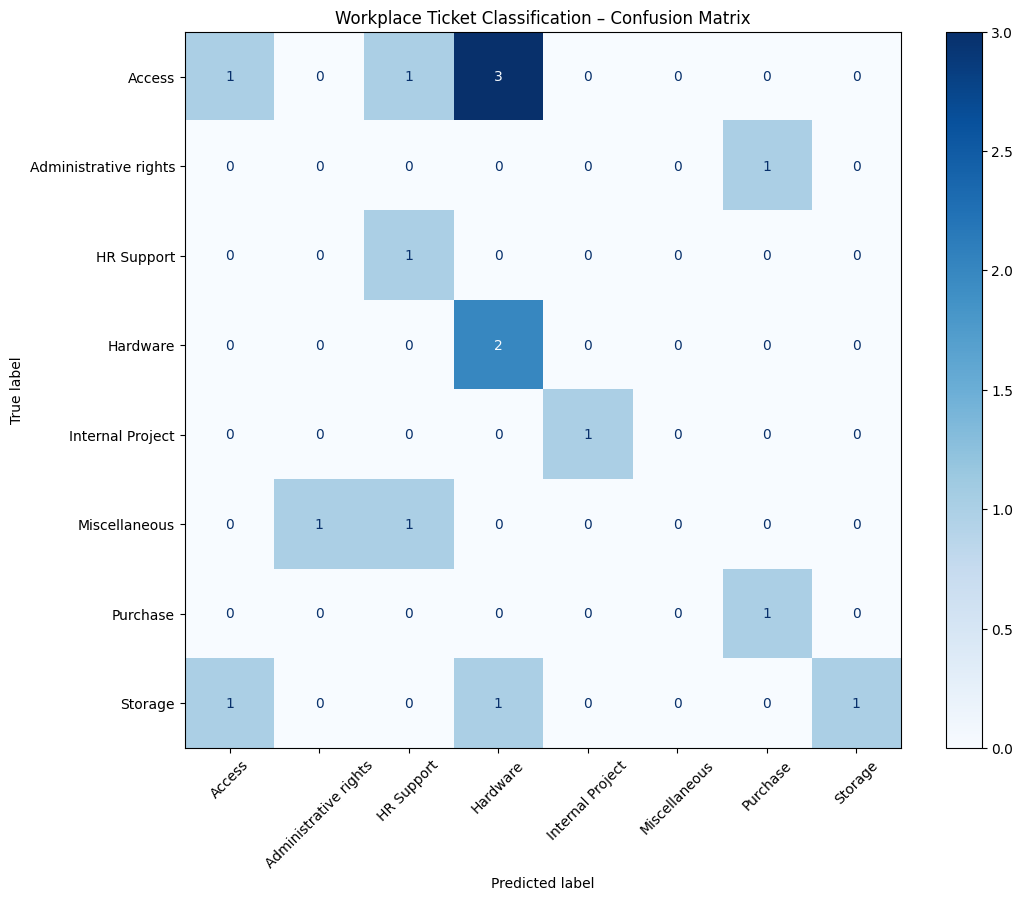

,Evaluation Dataset,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Original Held-out Test,0.8884,0.8936,0.8869,0.8901
1,Synthetic Workplace,0.4375,0.4583,0.5667,0.4315



Confusion matrix saved to: /content/drive/MyDrive/Cloud_IT_Support_Copilot/outputs/situated_learning/workplace_confusion_matrix.png
Metrics saved to: /content/drive/MyDrive/Cloud_IT_Support_Copilot/outputs/situated_learning/workplace_classification_metrics.json


In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import json

y_true = workplace_results_df["actual_category"]
y_pred = workplace_results_df["predicted_category"]

# Overall metrics
workplace_accuracy = accuracy_score(y_true, y_pred)

macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=label_names,
        average="macro",
        zero_division=0
    )
)

print("=" * 65)
print("WORKPLACE CLASSIFICATION EVALUATION")
print("=" * 65)

print(f"Accuracy:         {workplace_accuracy:.4f}")
print(f"Macro Precision:  {macro_precision:.4f}")
print(f"Macro Recall:     {macro_recall:.4f}")
print(f"Macro F1-score:   {macro_f1:.4f}")

# Per-category report
report = classification_report(
    y_true,
    y_pred,
    labels=label_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

display(report_df.round(3))

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=label_names
)

fig, ax = plt.subplots(figsize=(11, 9))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_names
)

disp.plot(
    ax=ax,
    xticks_rotation=45,
    cmap="Blues",
    values_format="d"
)

plt.title("Workplace Ticket Classification – Confusion Matrix")
plt.tight_layout()

confusion_matrix_path = (
    PROJECT_ROOT
    / "outputs"
    / "situated_learning"
    / "workplace_confusion_matrix.png"
)

plt.savefig(confusion_matrix_path, dpi=150, bbox_inches="tight")
plt.show()

# Compare original test and workplace performance
performance_comparison = pd.DataFrame([
    {
        "Evaluation Dataset": "Original Held-out Test",
        "Accuracy": finetuned_metrics["accuracy"],
        "Macro Precision": finetuned_metrics["macro_precision"],
        "Macro Recall": finetuned_metrics["macro_recall"],
        "Macro F1": finetuned_metrics["macro_f1"]
    },
    {
        "Evaluation Dataset": "Synthetic Workplace",
        "Accuracy": workplace_accuracy,
        "Macro Precision": macro_precision,
        "Macro Recall": macro_recall,
        "Macro F1": macro_f1
    }
])

display(performance_comparison.round(4))

# Save evaluation metrics
workplace_metrics = {
    "accuracy": float(workplace_accuracy),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "macro_f1": float(macro_f1),
    "classification_report": report
}

metrics_path = (
    PROJECT_ROOT
    / "outputs"
    / "situated_learning"
    / "workplace_classification_metrics.json"
)

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(workplace_metrics, f, indent=2)

print(f"\nConfusion matrix saved to: {confusion_matrix_path}")
print(f"Metrics saved to: {metrics_path}")

## Situated Learning – Evaluation of Summarisation and RAG Outputs

Evaluate the ticket summaries and RAG-generated troubleshooting responses produced for the synthetic workplace tickets.

Assess:
- Summary quality: whether the summary captures the reported issue, relevant details and required support action.
- RAG relevance: whether the retrieved documentation is relevant to the workplace ticket.
- Response quality: whether the generated guidance is useful and supported by retrieved evidence.

The evaluation will use qualitative ratings to identify strengths, limitations and opportunities for improvement.

In [ ]:
import json
import pandas as pd

# Load the saved workplace results
workplace_results_path = (
    PROJECT_ROOT
    / "outputs"
    / "situated_learning"
    / "workplace_copilot_results.json"
)

with open(workplace_results_path, "r", encoding="utf-8") as f:
    workplace_results = json.load(f)

# Prepare a review table
review_rows = []

for result in workplace_results:

    sources = result.get("retrieved_sources", [])
    evidence = result.get("retrieved_evidence", [])

    review_rows.append({
        "ticket_id": result["ticket_id"],
        "title": result["title"],
        "actual_category": result["actual_category"],
        "summary": result["summary"],
        "rag_answer": result["rag_answer"],
        "retrieved_documents": " | ".join(
            source["title"] for source in sources
        ),
        "top_similarity": (
            max(
                doc["similarity_score"]
                for doc in evidence
            )
            if evidence else None
        )
    })

workplace_review_df = pd.DataFrame(review_rows)

# Save review data for inspection
review_path = (
    PROJECT_ROOT
    / "outputs"
    / "situated_learning"
    / "workplace_summary_rag_review.csv"
)

workplace_review_df.to_csv(review_path, index=False)

print("=" * 70)
print("WORKPLACE SUMMARISATION AND RAG REVIEW")
print("=" * 70)

print(f"Tickets available for review: {len(workplace_review_df)}")
print(f"Review file saved to: {review_path}")

# Display a manageable sample first
for _, row in workplace_review_df.head(4).iterrows():

    print("\n" + "=" * 70)
    print(f"{row['ticket_id']} – {row['title']}")
    print("=" * 70)

    print("\nSUMMARY:")
    print(row["summary"])

    print("\nRAG RESPONSE:")
    print(row["rag_answer"])

    print("\nRETRIEVED DOCUMENTS:")
    print(row["retrieved_documents"])

    print(f"\nTop retrieval similarity: {row['top_similarity']}")

In [ ]:
# Display workplace tickets 5–8 for qualitative evaluation

for _, row in workplace_review_df.iloc[4:8].iterrows():

    print("\n" + "=" * 70)
    print(f"{row['ticket_id']} – {row['title']}")
    print("=" * 70)

    print("\nACTUAL CATEGORY:")
    print(row["actual_category"])

    print("\nGENERATED SUMMARY:")
    print(row["summary"])

    print("\nRAG RESPONSE:")
    print(row["rag_answer"])

    print("\nRETRIEVED DOCUMENTS:")
    print(row["retrieved_documents"])

    print(f"\nTop retrieval similarity: {row['top_similarity']}")

In [ ]:
# Display workplace tickets 9–12 for qualitative evaluation

for _, row in workplace_review_df.iloc[8:12].iterrows():

    print("\n" + "=" * 70)
    print(f"{row['ticket_id']} – {row['title']}")
    print("=" * 70)

    print("\nACTUAL CATEGORY:")
    print(row["actual_category"])

    print("\nGENERATED SUMMARY:")
    print(row["summary"])

    print("\nRAG RESPONSE:")
    print(row["rag_answer"])

    print("\nRETRIEVED DOCUMENTS:")
    print(row["retrieved_documents"])

    print(f"\nTop retrieval similarity: {row['top_similarity']}")

In [ ]:
# Display workplace tickets 13–16 for qualitative evaluation

for _, row in workplace_review_df.iloc[12:16].iterrows():

    print("\n" + "=" * 70)
    print(f"{row['ticket_id']} – {row['title']}")
    print("=" * 70)

    print("\nACTUAL CATEGORY:")
    print(row["actual_category"])

    print("\nGENERATED SUMMARY:")
    print(row["summary"])

    print("\nRAG RESPONSE:")
    print(row["rag_answer"])

    print("\nRETRIEVED DOCUMENTS:")
    print(row["retrieved_documents"])

    print(f"\nTop retrieval similarity: {row['top_similarity']}")

## Situated Learning – Consolidated Qualitative Evaluation

Consolidate the manual evaluation of all 16 workplace ticket summaries and RAG-generated responses.

Classify each output as Good, Partial or Poor based on its completeness, relevance and factual grounding.

Save the evaluation scorecard for use in the assignment report.

In [ ]:
# Manually assessed qualitative ratings for all 16 tickets.
# NOTE: the RAG ratings below describe the answers from the first run (500-word chunks, no threshold).
# After re-running with 150-word chunks, re-read the RAG answers (cells above) and update rag_ratings.

summary_ratings = {
    "SL-001": "Good",
    "SL-002": "Good",
    "SL-003": "Good",
    "SL-004": "Good",
    "SL-005": "Partial",
    "SL-006": "Good",
    "SL-007": "Good",
    "SL-008": "Good",
    "SL-009": "Good",
    "SL-010": "Good",
    "SL-011": "Good",
    "SL-012": "Partial",
    "SL-013": "Good",
    "SL-014": "Good",
    "SL-015": "Good",
    "SL-016": "Partial"
}

rag_ratings = {
    "SL-001": "Partial",
    "SL-002": "Poor",
    "SL-003": "Good",
    "SL-004": "Partial",
    "SL-005": "Good",
    "SL-006": "Partial",
    "SL-007": "Poor",
    "SL-008": "Good",
    "SL-009": "Partial",
    "SL-010": "Poor",
    "SL-011": "Poor",
    "SL-012": "Partial",
    "SL-013": "Partial",
    "SL-014": "Poor",
    "SL-015": "Poor",
    "SL-016": "Poor"
}

# Create consolidated scorecard
scorecard = workplace_results_df[
    [
        "ticket_id",
        "title",
        "actual_category",
        "predicted_category",
        "classification_correct"
    ]
].copy()

scorecard["summary_quality"] = scorecard["ticket_id"].map(
    summary_ratings
)

scorecard["rag_quality"] = scorecard["ticket_id"].map(
    rag_ratings
)

# Tickets for which the similarity threshold triggered an escalation message are
# reported as "Escalated" instead of being rated as an answer
escalated_map = dict(zip(
    workplace_results_df["ticket_id"],
    workplace_results_df["rag_insufficient"]
))
scorecard["rag_escalated"] = scorecard["ticket_id"].map(escalated_map)
scorecard.loc[scorecard["rag_escalated"] == True, "rag_quality"] = "Escalated"

# Display counts
print("=" * 65)
print("WORKPLACE COPILOT QUALITATIVE SCORECARD")
print("=" * 65)

for capability in ["summary_quality", "rag_quality"]:
    print(f"\n{capability.replace('_', ' ').title()}")

    print(
        scorecard[capability]
        .value_counts()
        .reindex(["Good", "Partial", "Poor", "Escalated"], fill_value=0)
        .to_string()
    )

# Save scorecard
scorecard_path = (
    PROJECT_ROOT
    / "outputs"
    / "situated_learning"
    / "workplace_qualitative_scorecard.csv"
)

scorecard.to_csv(scorecard_path, index=False)

print(f"\nScorecard saved to: {scorecard_path}")

display(scorecard)

## Situated Learning – Efficiency and Scalability Measurement

Each of the 16 workplace tickets is timed through the three stages (classification, summarisation and RAG) on the Colab GPU after a warm-up pass. The cell reports mean, median and 95th-percentile latency per stage, the share of time spent in text generation, peak GPU memory and the resulting single-GPU throughput. These measurements are used in the Analyse section.

In [ ]:
# ============================================================
# PER-TICKET LATENCY AND THROUGHPUT
# ============================================================
import time
import numpy as np
import pandas as pd
import torch
from IPython.display import display, Markdown


def _sync():
    if torch.cuda.is_available():
        torch.cuda.synchronize()


def timed(function, *args, **kwargs):
    _sync()
    start = time.perf_counter()
    output = function(*args, **kwargs)
    _sync()
    return output, time.perf_counter() - start


def classify_only(text):
    device = next(classifier_model.parameters()).device
    inputs = classifier_tokenizer(
        text, return_tensors="pt", truncation=True, max_length=256
    ).to(device)
    with torch.no_grad():
        logits = classifier_model(**inputs).logits
    return int(torch.argmax(logits, dim=-1).item())


# Warm-up so one-off CUDA initialisation is not counted
warm_text = workplace_df["description"].iloc[0]
classify_only(warm_text)
summarise_ticket(warm_text, max_new_tokens=20)
retrieve_documents(warm_text, top_k=5)

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

latency_rows = []

for _, ticket in workplace_df.iterrows():
    text = ticket["description"]

    _, t_classify = timed(classify_only, text)
    _, t_summarise = timed(summarise_ticket, text)
    rag_result, t_rag = timed(rag_answer, text, top_k=5, max_new_tokens=300)

    latency_rows.append({
        "ticket_id": ticket["ticket_id"],
        "ticket_words": len(text.split()),
        "classification_s": t_classify,
        "summarisation_s": t_summarise,
        "rag_s": t_rag,
        "total_s": t_classify + t_summarise + t_rag,
        "rag_escalated": bool(rag_result.get("insufficient", False))
    })

latency_df = pd.DataFrame(latency_rows)


def stage_stats(column):
    values = latency_df[column].to_numpy()
    return {
        "Mean (s)": values.mean(),
        "Median (s)": float(np.median(values)),
        "95th percentile (s)": float(np.percentile(values, 95)),
        "Max (s)": values.max()
    }


stats_df = pd.DataFrame({
    "Classification": stage_stats("classification_s"),
    "Summarisation": stage_stats("summarisation_s"),
    "RAG (retrieve + generate)": stage_stats("rag_s"),
    "End-to-end per ticket": stage_stats("total_s")
}).T.round(3)

mean_total = latency_df["total_s"].mean()
generation_share = (
    (latency_df["summarisation_s"].sum() + latency_df["rag_s"].sum())
    / latency_df["total_s"].sum()
)
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
peak_gpu_gb = (
    torch.cuda.max_memory_allocated() / (1024 ** 3) if torch.cuda.is_available() else float("nan")
)
n_escalated = int(latency_df["rag_escalated"].sum())

display(latency_df.round(3))
display(stats_df)

display(Markdown(
    f"### Measured efficiency ({gpu_name}, tickets processed one at a time, greedy decoding)\n\n"
    f"- Mean end-to-end time: **{mean_total:.2f} s per ticket** "
    f"(about **{3600 / mean_total:.0f} tickets per hour** per GPU in sequence).\n"
    f"- Summarisation and RAG generation account for **{generation_share:.0%}** of total time.\n"
    f"- Peak GPU memory during the run: **{peak_gpu_gb:.2f} GB**.\n"
    f"- {n_escalated} of {len(latency_df)} tickets were escalated by the similarity threshold "
    f"(these skip text generation, which lowers the RAG average)."
))

latency_df.to_csv(
    PROJECT_ROOT / "outputs" / "evaluation" / "latency_per_ticket.csv", index=False
)
stats_df.to_csv(
    PROJECT_ROOT / "outputs" / "evaluation" / "latency_summary.csv"
)


## Situated Learning – Workplace Application

### 1. Anchor – Workplace Context and Problem

**Organisation (close analogue).** The workplace used for this exercise is the IT service desk of a mid-sized enterprise software company. Employees in Engineering, Product, Finance, HR, Operations, Procurement and Sales raise support requests through a ticketing portal or by email. No real organisational data was used; the setting and the tickets are an analogue of a typical enterprise IT service-management (ITSM) desk.

**Current workflow (manual).**

1. An employee describes the problem in free text.
2. A first-line agent reads the ticket, manually assigns a category and priority, and routes it to the resolver group.
3. When the ticket is escalated or reassigned, the agent condenses the request into a handover note.
4. The agent searches the knowledge base, vendor documentation or earlier tickets for a fix.
5. The agent replies with the steps or escalates.

**Limitations of the current workflow.**

- Category assignment depends on the individual agent, so similar tickets are routed inconsistently, and mis-routed tickets bounce between teams and delay resolution.
- Long or poorly written tickets must be re-read at every hand-off.
- Knowledge-base search is keyword-based and slow, and routine questions (passwords, printers, storage) consume first-line time.
- Answers are not consistently tied to a documented source, which makes them hard to verify.

**Proposed AI solution and expected benefit.** The Cloud & IT Support Copilot pre-processes each ticket before an agent opens it: (1) a fine-tuned DistilBERT model proposes a category with a confidence score; (2) Qwen2.5-3B-Instruct produces a four-part structured summary; (3) a RAG assistant retrieves documentation and drafts a first response with cited sources, or escalates when the documentation is insufficient. The expected benefits are faster and more consistent triage, fewer mis-routed tickets, shorter hand-offs and quicker access to documented fixes, with the agent remaining the decision-maker. These benefits are hypotheses to be measured in a pilot using first-response time, reassignment rate, handling time and the share of suggestions agents accept. The prototype evaluation below tests only whether the outputs are accurate and useful enough to justify such a pilot.

To simulate this environment, 16 synthetic workplace support tickets covering the eight categories were created. They were not sourced from an actual organisation and are used to assess how the application performs on examples outside its training data.

### 2. Apply – Application of the Developed Models

The integrated pipeline behind the Gradio application (the same classification, summarisation and RAG functions that the interface calls) was run on the synthetic workplace tickets through three capabilities:

**Ticket classification:** The fine-tuned DistilBERT model predicted one of eight support categories for each ticket. The model correctly classified 7 out of 16 tickets, achieving 43.75% accuracy on the synthetic workplace sample.

**Ticket summarisation:** The Qwen2.5-3B-Instruct model generated structured summaries containing the reported issue, relevant details, troubleshooting performed and support action required. Of the 16 summaries manually reviewed, 13 were rated Good and 3 Partial.

**Knowledge-grounded support assistance:** The RAG component retrieved relevant passages from a knowledge base of Microsoft and Windows support documentation and used Qwen2.5-3B-Instruct to generate troubleshooting responses. In the initial run (500-word chunks, no similarity threshold), 3 of the 16 responses were rated Good, 6 Partial and 7 Poor.

The application therefore demonstrated all three capabilities in a single workflow, from categorising and summarising a ticket to generating a suggested support response.

**Workplace data sources.** In a production deployment the copilot would draw on (a) incoming and historical tickets from the service-management platform's export or API, (b) the organisation's internal wiki, runbooks and approved how-to articles as the knowledge base, and (c) the identity and asset systems for context such as the user's role and device type. In this prototype, (a) is represented by the 16 synthetic tickets and (b) by 16 public Microsoft support articles; (c) was not used.

### 3. Analyse – Results and Workplace Suitability

**Classification performance**

The fine-tuned classifier achieved 88.84% accuracy and 0.8901 macro F1 on the original held-out test set. However, its accuracy on the synthetic workplace tickets was only 43.75%.

This substantial difference indicates a generalisation gap between the original dataset and the simulated workplace scenarios. Some tickets were incorrectly categorised despite high prediction confidence. For example, the OneDrive storage synchronisation ticket was classified as Access, while the request for finance application access was classified as HR Support.

This demonstrates that prediction confidence should not be treated as evidence that a classification is correct. In a workplace setting, incorrect categorisation could result in tickets being routed to the wrong support team and delays in resolution.

**Summarisation performance**

Summarisation was the strongest capability in the workplace evaluation. Most outputs captured the reported problem and organised the available information into a consistent structure.

However, some summaries included inferred support actions that were not explicitly stated in the original ticket. Minor output-quality issues were also observed, including a typographical error in one summary. These findings indicate that generated summaries should be reviewed before being added to an official support record.

**RAG performance**

RAG performance was less consistent. In the initial run, only 3 of the 16 responses were rated Good, while 6 were Partial and 7 Poor.

The system performed better when the ticket matched the available Microsoft and Windows documentation. For example, the printer troubleshooting and Outlook search scenarios received relevant retrieved documentation and useful responses.

Performance deteriorated when tickets concerned topics outside the knowledge base. Examples included developer software installation, finance application access, purchase portal failures, HR time-record duplication and internal project code changes. In several cases, the retriever returned unrelated documents and the language model generated plausible but unsupported troubleshooting advice.

This highlights an important distinction: retrieving documents and generating a coherent response do not necessarily mean that the response is grounded in relevant evidence.

**Retrieval safeguard (similarity threshold)**

The unsupported answers led to a safeguard: when no retrieved chunk reaches a minimum similarity, the assistant does not call the language model and returns an "insufficient documentation, please escalate" message. In the initial run, ticket SL-002 (developer software installation) had a best similarity of only 0.27 and still received a confident answer, whereas relevant tickets scored higher (for example 0.52 for the password ticket). The threshold turns such cases into explicit escalations. The threshold audit table lists which tickets are escalated at the chosen value, and the scorecard records them as "Escalated" instead of rating guidance the knowledge base could not support.

**Efficiency and scalability**

Per-ticket latency was measured for each stage on the Colab T4 GPU (see the efficiency table above). Classification is a single forward pass of a small encoder, whereas summarisation and RAG each generate text token by token from a 4-bit 3B-parameter model, so the generation stages are expected to dominate end-to-end time; the table gives the measured split. Because tickets are processed one at a time on one GPU, throughput can only be raised by adding replicas, batching requests or using a serving engine with continuous batching. Vector search is negligible for 16 documents but must be re-measured on a realistic knowledge base of thousands of documents, and 4-bit quantisation saves memory at some cost in output quality. These figures come from a prototype on shared free-tier hardware and are indicative, not service-level numbers.

**Overall workplace suitability**

The prototype demonstrates the potential to reduce manual effort in ticket classification, summarisation and first-level troubleshooting. However, the evaluation shows that it is not sufficiently reliable to operate without human review. Classification errors and unsupported RAG recommendations could affect ticket routing and the quality of support provided to employees.

The evaluation is also limited by the small synthetic workplace sample and the narrow scope of the documentation corpus. The results should therefore be interpreted as an initial demonstration rather than evidence of performance in a live enterprise service desk.

### 4. Reflect – Deployment Constraints and Most Important Improvement

The exercise showed that fine-tuned classification, generative summarisation and retrieval-augmented generation together form a useful foundation for an IT support copilot, but the prototype is not ready for production. The main constraints are:

**Data privacy.** Tickets contain employee names, IDs and device details, and sometimes secrets pasted by users, such as recovery keys. Production use would need PII redaction before text is logged or sent to any model, data minimisation, defined retention periods, and a rule that ticket data stays inside the organisation's own tenant. The prototype ran open-weight models in a notebook and trained on a public, anonymised dataset, so no real data was exposed, but these controls were not tested. Its public `share=True` link would not be acceptable for real tickets.

**Security.** Ticket text is untrusted input placed directly into an LLM prompt, so a malicious or careless ticket could attempt prompt injection to alter a summary or steer a response. Production would need single sign-on and role-based access, input and output filtering, audit logging, and a hard rule that the copilot only suggests and never executes actions. The evaluation gave one concrete reason: in the initial RAG demo, a generated OneDrive answer advised deleting cached credential files, which the prompt's rule against destructive actions was meant to prevent.

**Regulation and compliance.** Depending on jurisdiction, processing employee data falls under data-protection law (for example the GDPR or India's Digital Personal Data Protection Act, 2023), so purpose limitation, access and erasure rights, and the use of ticket data for retraining would need review. Automated routing needs an audit trail, users should be told when text is AI-generated, and a named human must remain accountable for access and permission decisions. The organisation's information-security policies (for example ISO/IEC 27001 controls) would also apply.

**Infrastructure.** The prototype runs on a single free-tier Colab T4 GPU with a 4-bit 3B model, handles requests one at a time and is not persistent. Production would need a dedicated inference service (self-hosted GPU or managed endpoint), a persistent and refreshable vector store, model versioning, monitoring of accuracy and latency, autoscaling for peak ticket volumes, and a fallback to the manual queue if the service is unavailable. The measured per-ticket latency gives the starting point for capacity planning.

**Cost.** Running costs come from GPU hosting or per-token API fees, but the larger costs are people: curating and maintaining the knowledge base, labelling workplace tickets for retraining, reviewing outputs, and periodically re-evaluating the models. Self-hosting trades higher fixed cost and operations effort for control over data; a managed API trades the reverse. Neither was costed here because the prototype used free resources.

**Integration with existing systems.** The copilot would sit inside the existing service-management platform (for example ServiceNow, Jira Service Management or Freshservice) through its REST API or webhooks: read the new ticket, write the suggested category and summary into ticket fields, and post the drafted response as an internal note. It would also need the identity provider for access control, a scheduled sync from the organisation's wiki or document store into the vector index, and a feedback control so agents can accept or reject suggestions and those decisions feed future evaluation.

**Single most important improvement: an organisation-specific, validated knowledge base.** The knowledge base should cover the actual applications, internal processes, support policies and troubleshooting procedures the organisation uses. This addresses the largest limitation observed: the RAG component retrieved unrelated Microsoft documentation for problems that needed knowledge of HR, procurement or internal business applications, and the language model then produced plausible but unsupported advice.

It ranks above the alternatives for three reasons. Retraining the classifier on workplace tickets would improve routing, but a wrong category can be corrected by an agent, whereas guidance built on irrelevant documents can mislead the employee. The similarity threshold added after the evaluation can stop weak answers but cannot supply the missing content, so without relevant documents the assistant can only escalate. And a validated knowledge base also reduces the privacy and security risks above, because answers come from reviewed internal sources rather than general text patterns.

Even with this improvement, human review would remain important, particularly for access permissions, administrative changes and other actions that could affect business systems or employee data.



## Conclusion

The Cloud & IT Support Copilot demonstrates an integrated NLP-based approach to three IT support tasks: ticket classification, ticket summarisation and documentation-grounded troubleshooting.

The DistilBERT classifier was fine-tuned on 47,837 support tickets across eight categories. It improved accuracy from approximately 76.11% with the baseline model to 88.84% on the held-out test set. The Qwen2.5-3B-Instruct model was used to generate structured ticket summaries, while a Retrieval-Augmented Generation pipeline combined sentence-transformer embeddings, FAISS similarity search and Qwen2.5-3B-Instruct to answer support questions using retrieved documentation.

The capabilities were integrated into an interactive Gradio application and evaluated using a separate set of 16 synthetic workplace support tickets. The evaluation showed promising summarisation results, but also exposed limitations in classification generalisation and the grounding of generated troubleshooting responses.

Overall, the project demonstrates how fine-tuning and RAG can be combined in a practical AI support application. It also highlights the importance of representative training data, relevant knowledge sources and human review when applying generative AI to workplace support processes.
